# **Loading the raw data and Preprocessing**



*   Load the input file named "BrazosPlus2015_2024_County Addded.csv". This raw file provided by karthik(Gaiadhi). This data is derived from NOAA. We additionally created a column "County", to know which station belongs to which county.
*   Check the data availability per station and county. Eliminated the stations which has 100% missing data.



## **LOAD**

In [7]:
# prompt: mount drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
# Setting the current working directory
import os
os.chdir('/content/drive/MyDrive/')

In [9]:
path = "/content/drive/MyDrive/Gaiadhi"

In [10]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

In [46]:
# prompt: how to see files in the path

!ls /content/drive/MyDrive/Gaiadhi


'BrazosPlus2015_2024_County Added.csv'
 filtered_stations_data.csv
 FINAL_CODE_Brenham_TMAX_Prediction_saved.ipynb
 tl_2024_us_county.cpg
 tl_2024_us_county.dbf
 tl_2024_us_county.prj
 tl_2024_us_county.shp
 tl_2024_us_county.shp.ea.iso.xml
 tl_2024_us_county.shp.iso.xml
 tl_2024_us_county.shx


In [12]:
df = pd.read_csv("/content/drive/MyDrive/Gaiadhi/BrazosPlus2015_2024_County Added.csv")

In [13]:
df.head()

,Unnamed: 0,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,TMAX,TMIN,COUNTY
0,0,US1TXWA0030,"BRENHAM 1.7 SW, TX US",30.14367,-96.41901,119.5,9/22/2018,0.11,NaN,NaN,Washington County
1,1,US1TXWA0030,"BRENHAM 1.7 SW, TX US",30.14367,-96.41901,119.5,9/24/2018,0.00,NaN,NaN,Washington County
2,2,US1TXWA0030,"BRENHAM 1.7 SW, TX US",30.14367,-96.41901,119.5,9/25/2018,0.03,NaN,NaN,Washington County
3,3,US1TXWA0030,"BRENHAM 1.7 SW, TX US",30.14367,-96.41901,119.5,9/26/2018,0.03,NaN,NaN,Washington County
4,4,US1TXWA0030,"BRENHAM 1.7 SW, TX US",30.14367,-96.41901,119.5,9/29/2018,0.04,NaN,NaN,Washington County


In [14]:
df.shape

(176054, 11)

In [15]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [16]:
# Group by COUNTY and count the number of unique STATIONs and total rows
county_stats = df.groupby('COUNTY').agg({'STATION': 'nunique', 'COUNTY': 'count'})

# Rename columns for clarity
county_stats = county_stats.rename(columns={'STATION': 'Number of Stations', 'COUNTY': 'Number of Rows'})

county_stats


,Number of Stations,Number of Rows
COUNTY,,
Brazos County,32,34171
Burleson County,7,8317
Grimes County,8,7134
Leon County,6,5227
Madison County,3,3919
Milam County,37,48129
Robertson County,5,10176
Washington County,34,58981


In [17]:
# Calculate missing values for specific columns
missing_values = df.groupby('COUNTY')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Calculate total missing values per county
total_missing_per_county = missing_values.sum(axis=1)

# Calculate percentage of missing values per county
missing_percentage = (total_missing_per_county / df.groupby('COUNTY').size()) * 100

# Combine results into a single DataFrame
missing_data_summary = pd.DataFrame({
    'Number of Missing Rows': total_missing_per_county,
    'Missing Percentage': missing_percentage,
    'Missing PRCP': missing_values['PRCP'],
    'Missing TMIN': missing_values['TMIN'],
    'Missing TMAX': missing_values['TMAX']
})

missing_data_summary


,Number of Missing Rows,Missing Percentage,Missing PRCP,Missing TMIN,Missing TMAX
COUNTY,,,,,
Brazos County,61750,180.708788,774,30488,30488
Burleson County,10933,131.453649,319,5307,5307
Grimes County,14350,201.149425,82,7134,7134
Leon County,3350,64.090300,191,1598,1561
Madison County,1072,27.353917,125,476,471
Milam County,91571,190.261589,588,45491,45492
Robertson County,13480,132.468553,104,6688,6688
Washington County,101008,171.255150,1355,49833,49820


In [18]:
# Group by COUNTY and calculate number of unique stations and total rows
county_stats = df.groupby('COUNTY').agg(
    Number_of_Stations=('STATION', 'nunique'),
    Number_of_Rows=('COUNTY', 'count')
)

# Calculate missing values per column
missing_values = df.groupby('COUNTY')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Calculate total missing values and missing percentage
# Count rows where any of PRCP, TMIN, TMAX is missing
missing_any = df[['COUNTY', 'PRCP', 'TMIN', 'TMAX']].copy()
missing_any['missing_any'] = missing_any[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)

# Count missing rows per county
total_missing_per_county = missing_any.groupby('COUNTY')['missing_any'].sum()
missing_percentage = (total_missing_per_county / county_stats['Number_of_Rows']) * 100

# Combine all into one DataFrame
combined_stats = county_stats.copy()
combined_stats['Number of Missing Rows'] = total_missing_per_county
combined_stats['Missing Percentage'] = missing_percentage
combined_stats['Missing PRCP'] = missing_values['PRCP']
combined_stats['Missing TMIN'] = missing_values['TMIN']
combined_stats['Missing TMAX'] = missing_values['TMAX']

# Display final result
combined_stats


,Number_of_Stations,Number_of_Rows,Number of Missing Rows,Missing Percentage,Missing PRCP,Missing TMIN,Missing TMAX
COUNTY,,,,,,,
Brazos County,32,34171,30488,89.221855,774,30488,30488
Burleson County,7,8317,5587,67.175664,319,5307,5307
Grimes County,8,7134,7134,100.000000,82,7134,7134
Leon County,6,5227,1601,30.629424,191,1598,1561
Madison County,3,3919,598,15.258995,125,476,471
Milam County,37,48129,45563,94.668495,588,45491,45492
Robertson County,5,10176,6759,66.420991,104,6688,6688
Washington County,34,58981,50223,85.151150,1355,49833,49820


## **Filtering data countywise stations to check the missing value behavior and data availability**

In [19]:
# Filter data for Brazos County
brazos_df = df[df['COUNTY'] == 'Brazos County'].copy()

# Count missing values per station
missing_by_station = brazos_df.groupby('STATION')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Count rows where any value is missing (row-wise) per station
brazos_df['missing_any'] = brazos_df[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)
missing_rows_by_station = brazos_df.groupby('STATION')['missing_any'].sum()

# Total rows per station
total_rows_by_station = brazos_df.groupby('STATION').size()

# Calculate missing percentage per station
missing_percentage_by_station = (missing_rows_by_station / total_rows_by_station) * 100

# Combine all into one DataFrame
station_missing_summary = pd.DataFrame({
    'Total Rows': total_rows_by_station,
    'Missing Rows (Any)': missing_rows_by_station,
    'Missing % (Any)': missing_percentage_by_station,
    'Missing PRCP': missing_by_station['PRCP'],
    'Missing TMIN': missing_by_station['TMIN'],
    'Missing TMAX': missing_by_station['TMAX']
})

# Display result
station_missing_summary.sort_values(by='Missing % (Any)', ascending=False)


,Total Rows,Missing Rows (Any),Missing % (Any),Missing PRCP,Missing TMIN,Missing TMAX
STATION,,,,,,
US1TXBZS040,986,986,100.000000,6,986,986
US1TXBZS075,62,62,100.000000,0,62,62
US1TXBZS077,137,137,100.000000,5,137,137
US1TXBZS088,3489,3489,100.000000,135,3489,3489
US1TXBZS092,340,340,100.000000,12,340,340
US1TXBZS096,537,537,100.000000,2,537,537
US1TXBZS097,1071,1071,100.000000,173,1071,1071
US1TXBZS098,2840,2840,100.000000,39,2840,2840
US1TXBZS099,2921,2921,100.000000,15,2921,2921


In [20]:
# Filter data for Burleson County
Burleson_df = df[df['COUNTY'] == 'Burleson County'].copy()

# Count missing values per station
missing_by_station = Burleson_df.groupby('STATION')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Count rows where any value is missing (row-wise) per station
Burleson_df['missing_any'] = Burleson_df[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)
missing_rows_by_station = Burleson_df.groupby('STATION')['missing_any'].sum()

# Total rows per station
total_rows_by_station = Burleson_df.groupby('STATION').size()

# Calculate missing percentage per station
missing_percentage_by_station = (missing_rows_by_station / total_rows_by_station) * 100

# Combine all into one DataFrame
station_missing_summary = pd.DataFrame({
    'Total Rows': total_rows_by_station,
    'Missing Rows (Any)': missing_rows_by_station,
    'Missing % (Any)': missing_percentage_by_station,
    'Missing PRCP': missing_by_station['PRCP'],
    'Missing TMIN': missing_by_station['TMIN'],
    'Missing TMAX': missing_by_station['TMAX']
})

# Display result
station_missing_summary.sort_values(by='Missing % (Any)', ascending=False)


,Total Rows,Missing Rows (Any),Missing % (Any),Missing PRCP,Missing TMIN,Missing TMAX
STATION,,,,,,
US1TXBRL008,174,174,100.000000,25,174,174
US1TXBRL011,1362,1362,100.000000,1,1362,1362
US1TXBRL014,815,815,100.000000,0,815,815
US1TXBRL015,113,113,100.000000,0,113,113
US1TXBRL016,212,212,100.000000,8,212,212
USC00411314,2620,2620,100.000000,0,2620,2620
USC00418446,3021,291,9.632572,285,11,11


In [21]:
# Filter data for Grimes County
Grimes_df = df[df['COUNTY'] == 'Grimes County'].copy()

# Count missing values per station
missing_by_station = Grimes_df.groupby('STATION')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Count rows where any value is missing (row-wise) per station
Grimes_df['missing_any'] = Grimes_df[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)
missing_rows_by_station = Grimes_df.groupby('STATION')['missing_any'].sum()

# Total rows per station
total_rows_by_station = Grimes_df.groupby('STATION').size()

# Calculate missing percentage per station
missing_percentage_by_station = (missing_rows_by_station / total_rows_by_station) * 100

# Combine all into one DataFrame
station_missing_summary = pd.DataFrame({
    'Total Rows': total_rows_by_station,
    'Missing Rows (Any)': missing_rows_by_station,
    'Missing % (Any)': missing_percentage_by_station,
    'Missing PRCP': missing_by_station['PRCP'],
    'Missing TMIN': missing_by_station['TMIN'],
    'Missing TMAX': missing_by_station['TMAX']
})

# Display result
station_missing_summary.sort_values(by='Missing % (Any)', ascending=False)

,Total Rows,Missing Rows (Any),Missing % (Any),Missing PRCP,Missing TMIN,Missing TMAX
STATION,,,,,,
US1TXGM0003,5,5,100.0,0,5,5
US1TXGM0007,2978,2978,100.0,12,2978,2978
US1TXGM0008,248,248,100.0,0,248,248
US1TXGM0009,104,104,100.0,1,104,104
US1TXGM0011,1082,1082,100.0,4,1082,1082
US1TXGM0012,1372,1372,100.0,13,1372,1372
US1TXGM0013,655,655,100.0,36,655,655
US1TXGM0014,690,690,100.0,16,690,690


In [22]:
# Filter data for Leon County
Leon_df = df[df['COUNTY'] == 'Leon County'].copy()

# Count missing values per station
missing_by_station = Leon_df.groupby('STATION')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Count rows where any value is missing (row-wise) per station
Leon_df['missing_any'] = Leon_df[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)
missing_rows_by_station = Leon_df.groupby('STATION')['missing_any'].sum()

# Total rows per station
total_rows_by_station = Leon_df.groupby('STATION').size()

# Calculate missing percentage per station
missing_percentage_by_station = (missing_rows_by_station / total_rows_by_station) * 100

# Combine all into one DataFrame
station_missing_summary = pd.DataFrame({
    'Total Rows': total_rows_by_station,
    'Missing Rows (Any)': missing_rows_by_station,
    'Missing % (Any)': missing_percentage_by_station,
    'Missing PRCP': missing_by_station['PRCP'],
    'Missing TMIN': missing_by_station['TMIN'],
    'Missing TMAX': missing_by_station['TMAX']
})

# Display result
station_missing_summary.sort_values(by='Missing % (Any)', ascending=False)

,Total Rows,Missing Rows (Any),Missing % (Any),Missing PRCP,Missing TMIN,Missing TMAX
STATION,,,,,,
US1TXLN0003,133,133,100.000000,3,133,133
US1TXLN0006,486,486,100.000000,59,486,486
US1TXLN0008,612,612,100.000000,129,612,612
US1TXLN0010,132,132,100.000000,0,132,132
US1TXLN0011,192,192,100.000000,0,192,192
USC00411596,3672,46,1.252723,0,43,6


In [23]:
# Filter data for Madison County
Madison_df = df[df['COUNTY'] == 'Madison County'].copy()

# Count missing values per station
missing_by_station = Madison_df.groupby('STATION')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Count rows where any value is missing (row-wise) per station
Madison_df['missing_any'] = Madison_df[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)
missing_rows_by_station = Madison_df.groupby('STATION')['missing_any'].sum()

# Total rows per station
total_rows_by_station = Madison_df.groupby('STATION').size()

# Calculate missing percentage per station
missing_percentage_by_station = (missing_rows_by_station / total_rows_by_station) * 100

# Combine all into one DataFrame
station_missing_summary = pd.DataFrame({
    'Total Rows': total_rows_by_station,
    'Missing Rows (Any)': missing_rows_by_station,
    'Missing % (Any)': missing_percentage_by_station,
    'Missing PRCP': missing_by_station['PRCP'],
    'Missing TMIN': missing_by_station['TMIN'],
    'Missing TMAX': missing_by_station['TMAX']
})

# Display result
station_missing_summary.sort_values(by='Missing % (Any)', ascending=False)

,Total Rows,Missing Rows (Any),Missing % (Any),Missing PRCP,Missing TMIN,Missing TMAX
STATION,,,,,,
US1TXMDS002,250,250,100.00000,3,250,250
USC00415904,213,213,100.00000,0,213,213
USC00415477,3456,135,3.90625,122,13,8


In [24]:
# Filter data for Milam County
Milam_df = df[df['COUNTY'] == 'Milam County'].copy()

# Count missing values per station
missing_by_station = Milam_df.groupby('STATION')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Count rows where any value is missing (row-wise) per station
Milam_df['missing_any'] = Milam_df[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)
missing_rows_by_station = Milam_df.groupby('STATION')['missing_any'].sum()

# Total rows per station
total_rows_by_station = Milam_df.groupby('STATION').size()

# Calculate missing percentage per station
missing_percentage_by_station = (missing_rows_by_station / total_rows_by_station) * 100

# Combine all into one DataFrame
station_missing_summary = pd.DataFrame({
    'Total Rows': total_rows_by_station,
    'Missing Rows (Any)': missing_rows_by_station,
    'Missing % (Any)': missing_percentage_by_station,
    'Missing PRCP': missing_by_station['PRCP'],
    'Missing TMIN': missing_by_station['TMIN'],
    'Missing TMAX': missing_by_station['TMAX']
})

# Display result
station_missing_summary.sort_values(by='Missing % (Any)', ascending=False)

,Total Rows,Missing Rows (Any),Missing % (Any),Missing PRCP,Missing TMIN,Missing TMAX
STATION,,,,,,
US1TXMLM001,3679,3679,100.00000,3,3679,3679
US1TXMLM002,2633,2633,100.00000,5,2633,2633
US1TXMLM003,442,442,100.00000,2,442,442
US1TXMLM009,685,685,100.00000,4,685,685
US1TXMLM010,897,897,100.00000,28,897,897
US1TXMLM011,149,149,100.00000,0,149,149
US1TXMLM012,645,645,100.00000,3,645,645
US1TXMLM014,190,190,100.00000,14,190,190
US1TXMLM015,669,669,100.00000,15,669,669


In [25]:
# Filter data for Robertson County
Robertson_df = df[df['COUNTY'] == 'Robertson County'].copy()

# Count missing values per station
missing_by_station = Robertson_df.groupby('STATION')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Count rows where any value is missing (row-wise) per station
Robertson_df['missing_any'] = Robertson_df[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)
missing_rows_by_station = Robertson_df.groupby('STATION')['missing_any'].sum()

# Total rows per station
total_rows_by_station = Robertson_df.groupby('STATION').size()

# Calculate missing percentage per station
missing_percentage_by_station = (missing_rows_by_station / total_rows_by_station) * 100

# Combine all into one DataFrame
station_missing_summary = pd.DataFrame({
    'Total Rows': total_rows_by_station,
    'Missing Rows (Any)': missing_rows_by_station,
    'Missing % (Any)': missing_percentage_by_station,
    'Missing PRCP': missing_by_station['PRCP'],
    'Missing TMIN': missing_by_station['TMIN'],
    'Missing TMAX': missing_by_station['TMAX']
})

# Display result
station_missing_summary.sort_values(by='Missing % (Any)', ascending=False)

,Total Rows,Missing Rows (Any),Missing % (Any),Missing PRCP,Missing TMIN,Missing TMAX
STATION,,,,,,
US1TXRT0003,1352,1352,100.000000,8,1352,1352
US1TXRT0004,1115,1115,100.000000,22,1115,1115
US1TXRT0005,606,606,100.000000,1,606,606
USC00411045,3466,3466,100.000000,0,3466,3466
USW00053973,3637,220,6.048941,73,149,149


In [26]:
# Filter data for Washington County
Washington_df = df[df['COUNTY'] == 'Washington County'].copy()

# Count missing values per station
missing_by_station = Washington_df.groupby('STATION')[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Count rows where any value is missing (row-wise) per station
Washington_df['missing_any'] = Washington_df[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)
missing_rows_by_station = Washington_df.groupby('STATION')['missing_any'].sum()

# Total rows per station
total_rows_by_station = Washington_df.groupby('STATION').size()

# Calculate missing percentage per station
missing_percentage_by_station = (missing_rows_by_station / total_rows_by_station) * 100

# Combine all into one DataFrame
station_missing_summary = pd.DataFrame({
    'Total Rows': total_rows_by_station,
    'Missing Rows (Any)': missing_rows_by_station,
    'Missing % (Any)': missing_percentage_by_station,
    'Missing PRCP': missing_by_station['PRCP'],
    'Missing TMIN': missing_by_station['TMIN'],
    'Missing TMAX': missing_by_station['TMAX']
})

# Display result
station_missing_summary.sort_values(by='Missing % (Any)', ascending=False)

,Total Rows,Missing Rows (Any),Missing % (Any),Missing PRCP,Missing TMIN,Missing TMAX
STATION,,,,,,
US1TXWA0001,3635,3635,100.000000,21,3635,3635
US1TXWA0003,1370,1370,100.000000,4,1370,1370
US1TXWA0005,657,657,100.000000,0,657,657
US1TXWA0006,3686,3686,100.000000,0,3686,3686
US1TXWA0008,406,406,100.000000,64,406,406
US1TXWA0009,3686,3686,100.000000,0,3686,3686
US1TXWA0010,2181,2181,100.000000,0,2181,2181
US1TXWA0012,1374,1374,100.000000,48,1374,1374
US1TXWA0014,3299,3299,100.000000,103,3299,3299


## **Countywise data availability**



*   Filtered the countywise data availability and exported to csv file named "filtered_stations_data.csv"



In [27]:
# Step 1: Create a column to flag any missing value in PRCP, TMIN, or TMAX
df['missing_any'] = df[['PRCP', 'TMIN', 'TMAX']].isnull().any(axis=1)

# Step 2: Group by COUNTY and STATION
grouped = df.groupby(['COUNTY', 'STATION'])

# Step 3: Compute total rows and missing rows (any)
total_rows = grouped.size()
missing_rows = grouped['missing_any'].sum()

# Step 4: Compute missing percentage
missing_percentage = (missing_rows / total_rows) * 100

# Step 5: Count missing values for each column
missing_counts = grouped[['PRCP', 'TMIN', 'TMAX']].apply(lambda x: x.isnull().sum())

# Step 6: Combine all into a DataFrame
station_missing_all = pd.DataFrame({
    'Total Rows': total_rows,
    'Missing Rows (Any)': missing_rows,
    'Missing % (Any)': missing_percentage,
    'Missing PRCP': missing_counts['PRCP'],
    'Missing TMIN': missing_counts['TMIN'],
    'Missing TMAX': missing_counts['TMAX']
})

# Step 7: Filter to exclude stations with 100% missing rows
station_missing_filtered = station_missing_all[station_missing_all['Missing % (Any)'] < 100]

# Optional: Reset index for a cleaner display
station_missing_filtered = station_missing_filtered.reset_index()

# Show result
station_missing_filtered



,COUNTY,STATION,Total Rows,Missing Rows (Any),Missing % (Any),Missing PRCP,Missing TMIN,Missing TMAX
0,Brazos County,USW00003904,3686,3,0.081389,1,3,3
1,Burleson County,USC00418446,3021,291,9.632572,285,11,11
2,Leon County,USC00411596,3672,46,1.252723,0,43,6
3,Madison County,USC00415477,3456,135,3.906250,122,13,8
4,Milam County,USW00000351,2686,120,4.467610,71,48,49
5,Robertson County,USW00053973,3637,220,6.048941,73,149,149
6,Washington County,USC00411048,3648,205,5.619518,168,146,152
7,Washington County,USC00419491,2204,142,6.442831,45,131,112
8,Washington County,USW00053928,3598,345,9.588660,344,25,25


In [28]:
# Step 1: Get list of valid (non-100% missing) stations by county
valid_stations = station_missing_filtered[['COUNTY', 'STATION']]

# Step 2: Merge with original dataset to filter it
filtered_df = df.merge(valid_stations, on=['COUNTY', 'STATION'], how='inner')

# Step 3: Select and reorder columns to match the original structure
final_df = filtered_df[['STATION', 'NAME', 'LATITUDE', 'LONGITUDE', 'ELEVATION',
                        'DATE', 'PRCP', 'TMAX', 'TMIN', 'COUNTY']]

# Display result
final_df.head()


,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,TMAX,TMIN,COUNTY
0,USW00053973,"HEARNE MUNICIPAL AIRPORT, TX US",30.87194,-96.62222,86.9,1/1/2015,0.62,41.0,36.0,Robertson County
1,USW00053973,"HEARNE MUNICIPAL AIRPORT, TX US",30.87194,-96.62222,86.9,1/2/2015,0.18,45.0,40.0,Robertson County
2,USW00053973,"HEARNE MUNICIPAL AIRPORT, TX US",30.87194,-96.62222,86.9,1/3/2015,1.49,53.0,35.0,Robertson County
3,USW00053973,"HEARNE MUNICIPAL AIRPORT, TX US",30.87194,-96.62222,86.9,1/4/2015,0.00,44.0,28.0,Robertson County
4,USW00053973,"HEARNE MUNICIPAL AIRPORT, TX US",30.87194,-96.62222,86.9,1/5/2015,0.00,49.0,23.0,Robertson County


In [29]:
final_df.shape

(29608, 10)

In [30]:
final_df.tail()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,TMAX,TMIN,COUNTY
29603,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,1/29/2025,0.07,58.0,45.0,Washington County
29604,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,1/30/2025,0.03,71.0,58.0,Washington County
29605,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,1/31/2025,0.21,72.0,53.0,Washington County
29606,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,2/1/2025,0.00,72.0,40.0,Washington County
29607,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,2/2/2025,0.00,78.0,40.0,Washington County


In [58]:
final_df.to_csv('/content/drive/MyDrive/Gaiadhi/filtered_stations_data.csv', index=False)


## **Handling the missing values in filtered stations data**



*   The input data file is "filtered_stations_data.csv"




In [32]:
#path = "/content/drive/MyDrive/Gaiadhi/filtered_stations_data.csv"
#df = pd.read_csv(path)

In [33]:
df=final_df

In [34]:
df.isnull().sum()

,0
STATION,0
NAME,0
LATITUDE,0
LONGITUDE,0
ELEVATION,0
DATE,0
PRCP,1109
TMAX,515
TMIN,569
COUNTY,0


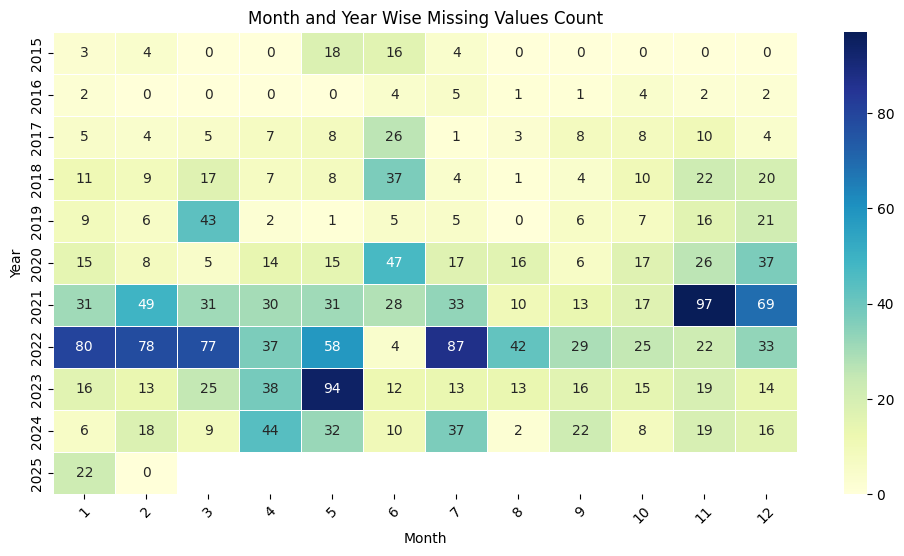

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is the DataFrame and has a 'DATE' column
# Convert 'DATE' column to datetime format
df['DATE'] = pd.to_datetime(df['DATE'])

# Extract Year and Month
df['Year'] = df['DATE'].dt.year
df['Month'] = df['DATE'].dt.month

# Group by Year and Month and count only missing values
missing_counts = df.groupby(['Year', 'Month']).apply(lambda x: x.isnull().sum().sum()).reset_index(name='Missing_Values')

# Pivot for heatmap
missing_pivot = missing_counts.pivot(index='Year', columns='Month', values='Missing_Values')

# Plot Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(missing_pivot, annot=True, fmt="g", cmap="YlGnBu", linewidths=0.5)
plt.title("Month and Year Wise Missing Values Count")
plt.xlabel("Month")
plt.ylabel("Year")
plt.xticks(rotation=45)
plt.show()

In [36]:
# prompt: yearwise missng values count print

# Assuming 'df' is the DataFrame and has a 'DATE' column
# Convert 'DATE' column to datetime format
df['DATE'] = pd.to_datetime(df['DATE'])

# Extract Year
df['Year'] = df['DATE'].dt.year

# Group by Year and count missing values for each year
missing_values_per_year = df.groupby('Year').apply(lambda x: x.isnull().sum().sum()).reset_index(name='Missing Values Count')

# Print the result
missing_values_per_year


,Year,Missing Values Count
0,2015,45
1,2016,21
2,2017,89
3,2018,150
4,2019,121
5,2020,223
6,2021,439
7,2022,572
8,2023,288
9,2024,223


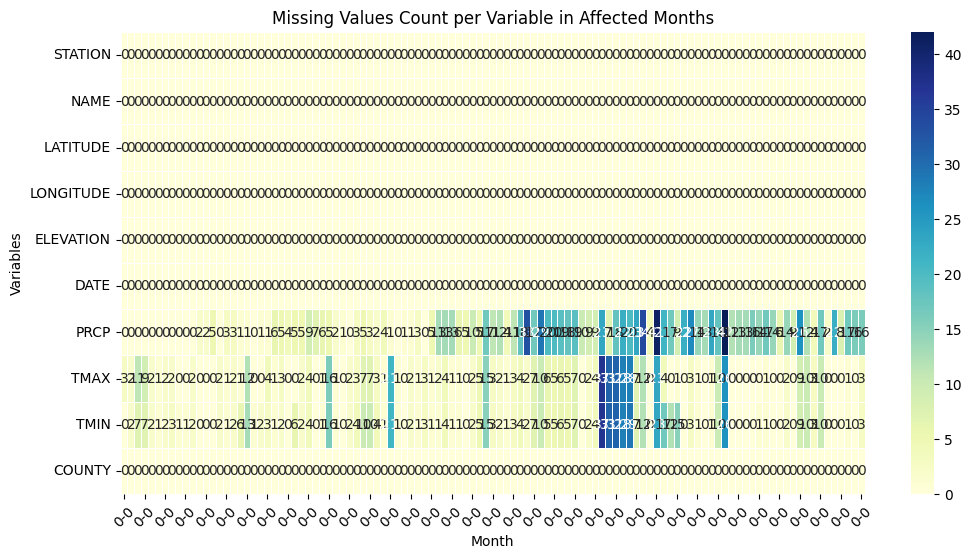

In [37]:
# Filter dataset to only include rows where there are missing values
missing_months = df[df.isnull().any(axis=1)]

# Group by Year and Month and count missing values for each column
missing_variables = (
    missing_months.groupby(['Year', 'Month'], as_index=False)
    .apply(lambda x: x.isnull().sum(numeric_only=True))
)

# Ensure no duplicate column names exist
missing_variables = missing_variables.loc[:, ~missing_variables.columns.duplicated()]

# Pivot for heatmap
missing_pivot = missing_variables.set_index(['Year', 'Month']).T

# Plot Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(missing_pivot, annot=True, fmt="g", cmap="YlGnBu", linewidths=0.5)
plt.title("Missing Values Count per Variable in Affected Months")
plt.xlabel("Month")
plt.ylabel("Variables")
plt.xticks(rotation=45)
plt.show()


### **Plotting station locations on the map**

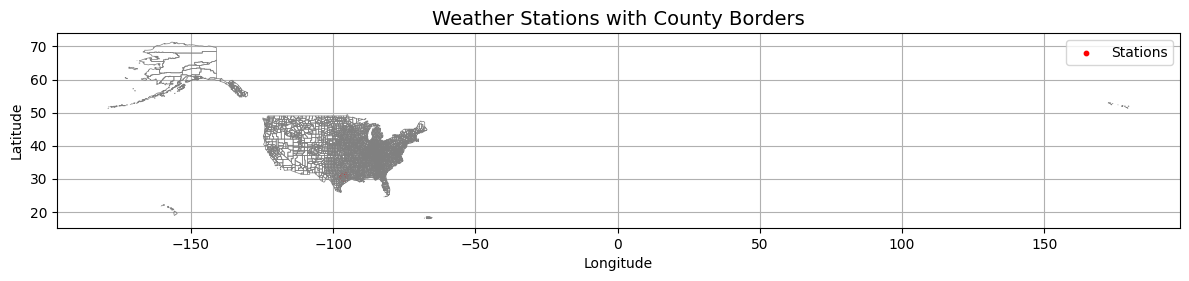

In [47]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# # 1. Load station dataset (already preprocessed)
# stations_df = pd.read_csv('/content/drive/MyDrive/Gaiadhi/filtered_stations_data.csv')

# 2. Load US county shapefile (Geopandas has a built-in source via Natural Earth)
# You can also use a local shapefile if needed
# For U.S. counties, use this from TIGER/Line or other GIS source
# Example: https://www2.census.gov/geo/tiger/TIGER2022/COUNTY/

# If you already have a county shapefile, load it like this:
# counties_gdf = gpd.read_file('/path/to/county_shapefile.shp')

# Or use a sample shapefile (US counties - from public datasets)
counties_gdf = gpd.read_file('https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json')

# Optional: If your county names don't match, use a standard U.S. shapefile instead
# or provide your own county shapefile that includes "NAME" column for matching

# 3. Convert stations DataFrame to GeoDataFrame
stations_gdf = gpd.GeoDataFrame(
    final_df,
    geometry=gpd.points_from_xy(final_df['LONGITUDE'], final_df['LATITUDE']),
    crs="EPSG:4326"  # WGS84
)

# 4. Plotting
fig, ax = plt.subplots(figsize=(12, 10))

# Plot counties (as borders)
counties_gdf.boundary.plot(ax=ax, linewidth=0.5, color='gray')

# Plot station locations
stations_gdf.plot(ax=ax, color='red', markersize=10, label='Stations')

# Customize
plt.title("Weather Stations with County Borders", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


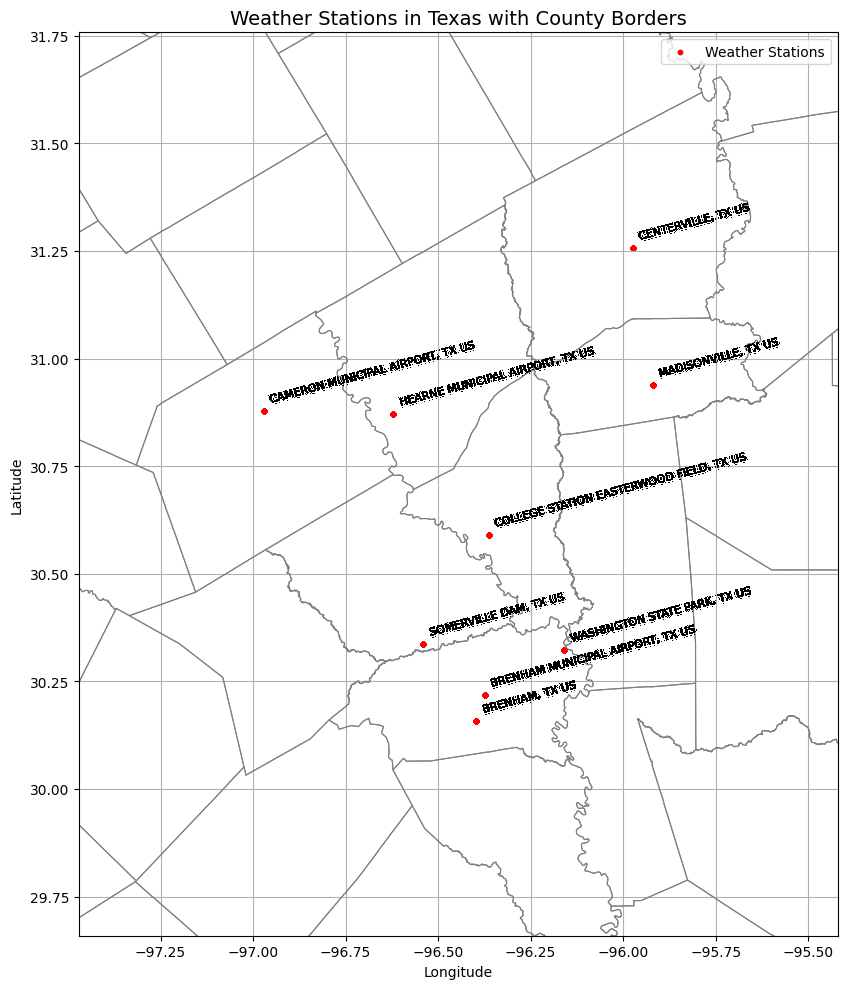

In [53]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# # 1. Load the weather station data
# stations_df = pd.read_csv('/content/drive/MyDrive/Gaiadhi/filtered_stations_data.csv')

# 2. Convert to GeoDataFrame
stations_gdf = gpd.GeoDataFrame(
    final_df,
    geometry=gpd.points_from_xy(final_df['LONGITUDE'], final_df['LATITUDE']),
    crs="EPSG:4326"
)

# 3. Load the U.S. county shapefile
# Use the path where your uploaded files are
counties_gdf = gpd.read_file('/content/drive/MyDrive/Gaiadhi/tl_2024_us_county.shp')


# 4. Filter to Texas counties only (Texas FIPS code = '48')
# Filter to Texas counties
texas_counties = counties_gdf[counties_gdf['STATEFP'] == '48']


# 5. Compute bounds from station locations to zoom in
buffer = 0.5  # add padding around the station area
minx, miny, maxx, maxy = stations_gdf.total_bounds
xlim = (minx - buffer, maxx + buffer)
ylim = (miny - buffer, maxy + buffer)

# 6. Plot Texas county borders and station locations
fig, ax = plt.subplots(figsize=(12, 10))

# Plot county borders
texas_counties.boundary.plot(ax=ax, linewidth=0.8, edgecolor='gray')

# Plot weather stations
stations_gdf.plot(ax=ax, color='red', markersize=10, label='Weather Stations')

# Add station names  (Added to get the station names)
for idx, row in stations_gdf.iterrows():
    ax.text(row.geometry.x + 0.02, row.geometry.y + 0.02, str(row['NAME']), fontsize=8, color='black',rotation=15,rotation_mode='anchor')

# Set zoom
ax.set_xlim(xlim)
ax.set_ylim(ylim)

# Beautify
plt.title("Weather Stations in Texas with County Borders", fontsize=14)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

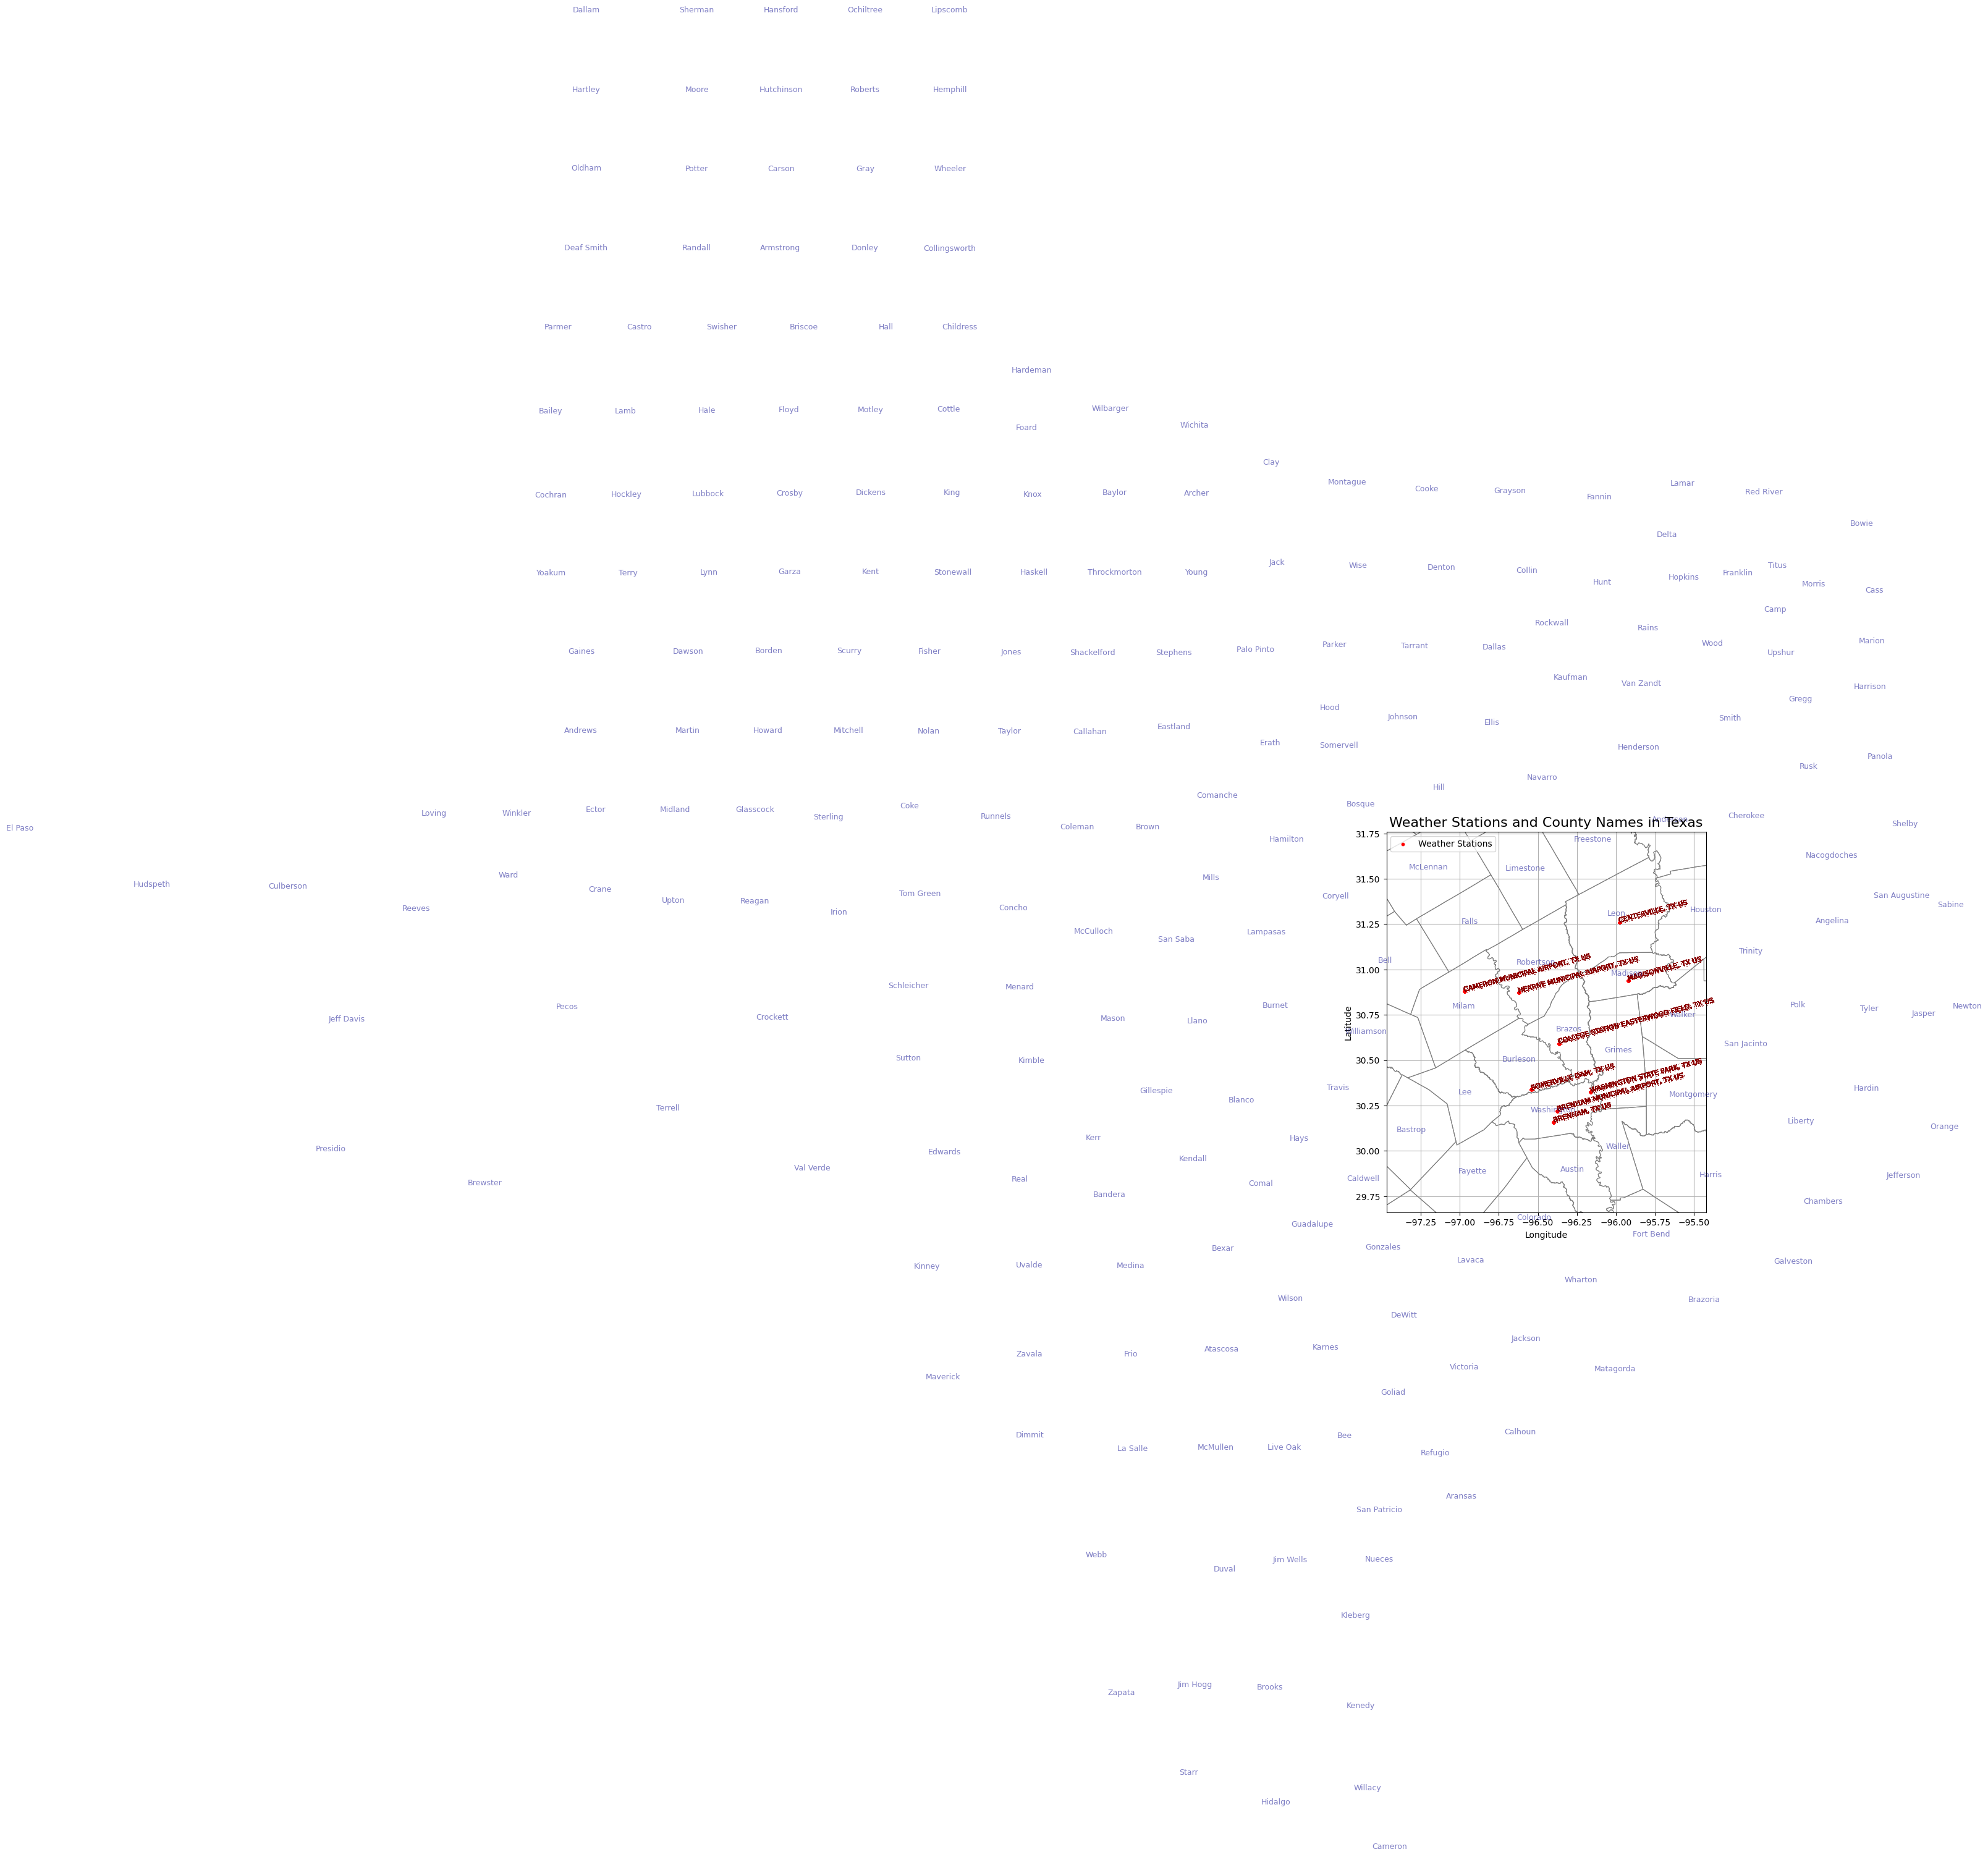

In [52]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

# # 1. Load the weather station data
# stations_df = pd.read_csv('/content/drive/MyDrive/Gaiadhi/filtered_stations_data.csv')

# 2. Convert to GeoDataFrame
stations_gdf = gpd.GeoDataFrame(
    final_df,
    geometry=gpd.points_from_xy(final_df['LONGITUDE'], final_df['LATITUDE']),
    crs="EPSG:4326"
)

# 3. Load the U.S. county shapefile
counties_gdf = gpd.read_file('/content/drive/MyDrive/Gaiadhi/tl_2024_us_county.shp')

# 4. Filter to Texas counties only (FIPS code 48)
texas_counties = counties_gdf[counties_gdf['STATEFP'] == '48']

# 5. Plot
fig, ax = plt.subplots(figsize=(10, 8))

# Plot counties
texas_counties.boundary.plot(ax=ax, linewidth=0.8, edgecolor='gray')

# Plot stations
stations_gdf.plot(ax=ax, color='red', markersize=10, label='Weather Stations')

# Add station labels
for x, y, name in zip(stations_gdf.geometry.x, stations_gdf.geometry.y, stations_gdf['NAME']):
    ax.text(x, y, name, fontsize=8, color='darkred', alpha=0.7,rotation=15,rotation_mode='anchor')

# Add county labels (using centroid of each county)
texas_counties['centroid'] = texas_counties.geometry.centroid
for x, y, name in zip(texas_counties['centroid'].x, texas_counties['centroid'].y, texas_counties['NAME']):
    ax.text(x, y, name, fontsize=9, color='darkblue', alpha=0.5, ha='center')

# Zoom in based on stations
buffer = 0.5
minx, miny, maxx, maxy = stations_gdf.total_bounds
ax.set_xlim(minx - buffer, maxx + buffer)
ax.set_ylim(miny - buffer, maxy + buffer)

# Final touches
plt.title("Weather Stations and County Names in Texas", fontsize=16)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# **Imputing the missing values from nearest 3 stations data**



*   After imputing the data, it is exported to csv file named "imputed_stations_data.csv"


In [54]:
import pandas as pd
import numpy as np
from sklearn.neighbors import BallTree

In [55]:
import pandas as pd
import numpy as np
from sklearn.neighbors import BallTree

# Load and prepare data
#df = pd.read_csv('/content/drive/MyDrive/Gaiadhi/filtered_stations_data.csv')
df=final_df
df['DATE'] = pd.to_datetime(df['DATE'])

# Add radians for haversine distance
df['lat_rad'] = np.radians(df['LATITUDE'])
df['lon_rad'] = np.radians(df['LONGITUDE'])

coords = df[['lat_rad', 'lon_rad']].values
tree = BallTree(coords, metric='haversine')

# Build a lookup to speed up queries
station_groups = df.groupby('STATION')

def find_closest_value(station_df, target_date, column):
    """Find value on the closest date with a non-null value"""
    station_df = station_df[['DATE', column]].dropna()
    if station_df.empty:
        return None
    # Find row with minimum date difference
    closest_row = station_df.loc[(station_df['DATE'] - target_date).abs().idxmin()]
    return closest_row[column]

def impute_spatial_temporal(df, column, k=3):
    missing_indices = df[df[column].isnull()].index
    imputed_count = 0

    for idx in missing_indices:
        row = df.loc[idx]
        target_date = row['DATE']
        point = np.array([[row['lat_rad'], row['lon_rad']]])

        # Find nearest neighbors (exclude self)
        dists, inds = tree.query(point, k=k+1)
        neighbors_idx = inds[0][inds[0] != idx]

        neighbor_values = []
        for neighbor_idx in neighbors_idx:
            neighbor_station = df.loc[neighbor_idx, 'STATION']
            station_df = station_groups.get_group(neighbor_station)
            val = find_closest_value(station_df, target_date, column)
            if val is not None:
                neighbor_values.append(val)

        if neighbor_values:
            df.at[idx, column] = np.mean(neighbor_values)
            imputed_count += 1

    print(f"{column}: {imputed_count} values imputed using 3 nearest stations with nearest-date values.")
    return df

# Run the imputation
for col in ['PRCP', 'TMIN', 'TMAX']:
    df = impute_spatial_temporal(df, col, k=3)

# Drop helper columns
df.drop(columns=['lat_rad', 'lon_rad'], inplace=True)




PRCP: 1109 values imputed using 3 nearest stations with nearest-date values.
TMIN: 569 values imputed using 3 nearest stations with nearest-date values.
TMAX: 515 values imputed using 3 nearest stations with nearest-date values.


In [56]:
df.isnull().sum()

,0
STATION,0
NAME,0
LATITUDE,0
LONGITUDE,0
ELEVATION,0
DATE,0
PRCP,0
TMAX,0
TMIN,0
COUNTY,0


In [57]:
df.to_csv('/content/drive/MyDrive/Gaiadhi/imputed_stations_data.csv', index=False)

# **Model Building - Brenham, TX station - TMAX**

*   We downlaoed the solar radiation data from NASA POWER for respective coordinates,

*   Using Excel functions, manually we added solar radiation based on stations(coordinates) to "imputed_stations_data" and Renamed the file as "imputed_all_stations_data.csv"

*   Input file: imputed_all_stations_data.csv (this file has Solar radiation)



## **Load the data and filterout Brenham**

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
# # prompt: mount drive

# from google.colab import drive
# drive.mount('/content/drive') # Replacing space with underscore or removing it altogether

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [61]:
# prompt: how to check it the path is read

import os
path = "/content/drive/MyDrive/Gaiadhi/imputed_all_stations_data.csv"
if os.path.exists(path):
  print(f"The file exists at {path}")
else:
  print(f"The file does not exist at {path}")


The file exists at /content/drive/MyDrive/Gaiadhi/imputed_all_stations_data.csv


In [62]:
# Load the dataset
df = pd.read_csv("/content/drive/MyDrive/Gaiadhi/imputed_all_stations_data.csv")

# Filter rows where station is "USC00411048"
brenham_df = df[df['STATION'] == "USC00411048"]

brenham_df.head()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,TMAX,TMIN,COUNTY,SOLAR RADIATION
23756,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,1/1/2015,0.11,43,37,Washington County,2.71
23757,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,1/2/2015,0.43,43,37,Washington County,2.73
23758,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,1/3/2015,0.72,45,41,Washington County,7.59
23759,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,1/4/2015,0.00,54,39,Washington County,14.06
23760,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,1/5/2015,0.00,48,27,Washington County,14.96


Splitting data into train and test

In [68]:
# Ensure the DATE column is datetime type
brenham_df['DATE'] = pd.to_datetime(brenham_df['DATE'])

# Sort by DATE to maintain time order
brenham_df = brenham_df.sort_values(by='DATE').reset_index(drop=True)

# Calculate split index
split_index = int(len(brenham_df) * 0.9)

# Split into train and test
train_df = brenham_df.iloc[:split_index].copy()
test_df = brenham_df.iloc[split_index:].copy()

In [69]:
train_df.shape

(3283, 11)

In [70]:
test_df.shape

(365, 11)

In [71]:
train_df.head()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,TMAX,TMIN,COUNTY,SOLAR RADIATION
0,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,2015-01-01,0.11,43,37,Washington County,2.71
1,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,2015-01-02,0.43,43,37,Washington County,2.73
2,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,2015-01-03,0.72,45,41,Washington County,7.59
3,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,2015-01-04,0.00,54,39,Washington County,14.06
4,USC00411048,"BRENHAM, TX US",30.1591,-96.3972,95.4,2015-01-05,0.00,48,27,Washington County,14.96


In [ ]:
numeric_cols = ['LATITUDE','LONGITUDE','ELEVATION','PRCP','TMAX','TMIN','SOLAR RADIATION']
filtered_df = train_df[numeric_cols]

# Drop constant columns (zero variance)
filtered_df = filtered_df.loc[:, filtered_df.nunique() > 1]

# Compute correlation matrix again
correlation_matrix = filtered_df.corr()

correlation_matrix.head()



,PRCP,TMAX,TMIN,SOLAR RADIATION
PRCP,1.000000,-0.068692,0.018050,-0.141203
TMAX,-0.068692,1.000000,0.882853,0.577400
TMIN,0.018050,0.882853,1.000000,0.472792
SOLAR RADIATION,-0.141203,0.577400,0.472792,1.000000


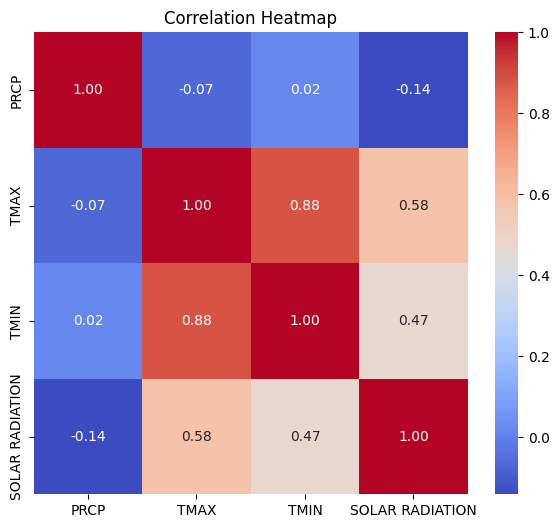

In [ ]:

import seaborn as sns

plt.figure(figsize=(7, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()


## **RandomForestRegressor**

### **Train and Predict on Test set**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt


# Add temporal features
for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

# Add lag and trend features to train
for lag in range(1, 8):
    train_df[f'TMAX_lag_{lag}'] = train_df['TMAX'].shift(lag)
    train_df[f'TMIN_lag_{lag}'] = train_df['TMIN'].shift(lag)
    train_df[f'PRCP_lag_{lag}'] = train_df['PRCP'].shift(lag)
train_df['TMAX_3day_avg'] = train_df['TMAX'].rolling(3).mean()
train_df['PRCP_3day_sum'] = train_df['PRCP'].rolling(3).sum()
train_df['TMAX_trend'] = train_df['TMAX'] - train_df['TMAX'].shift(1)
train_df.dropna(inplace=True)

# Add the same lag/trend features to test
for lag in range(1, 8):
    test_df[f'TMAX_lag_{lag}'] = test_df['TMAX'].shift(lag)
    test_df[f'TMIN_lag_{lag}'] = test_df['TMIN'].shift(lag)
    test_df[f'PRCP_lag_{lag}'] = test_df['PRCP'].shift(lag)
test_df['TMAX_3day_avg'] = test_df['TMAX'].rolling(3).mean()
test_df['PRCP_3day_sum'] = test_df['PRCP'].rolling(3).sum()
test_df['TMAX_trend'] = test_df['TMAX'] - test_df['TMAX'].shift(1)
test_df.dropna(inplace=True)

# Feature columns
feature_cols = ['TMIN', 'PRCP', 'SOLAR RADIATION', 'Month', 'DayOfYear', 'WeekOfYear',
                'DayOfWeek', 'IsWeekend', 'TMAX_3day_avg', 'PRCP_3day_sum', 'TMAX_trend'] + \
               [f'TMAX_lag_{i}' for i in range(1, 8)] + \
               [f'TMIN_lag_{i}' for i in range(1, 8)] + \
               [f'PRCP_lag_{i}' for i in range(1, 8)]

# Split 90/10 from train_df for tuning
X = train_df[feature_cols]
y = train_df['TMAX']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, shuffle=False)

# Hyperparameter tuning
param_dist = {
    'n_estimators': list(range(100, 400, 50)),
    'max_depth': [3, 5, 7, 9]
}
rf_model = RandomForestRegressor(random_state=42)
search = RandomizedSearchCV(rf_model, param_distributions=param_dist, n_iter=20,
                            scoring='neg_mean_squared_error', cv=3, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
best_model = search.best_estimator_

# Predict full test set
X_test = test_df[feature_cols]
y_test = test_df['TMAX']
test_df['Predicted_TMAX'] = best_model.predict(X_test)


Fitting 3 folds for each of 20 candidates, totalling 60 fits


In [ ]:
# Save to CSV
output_df = test_df[['DATE', 'TMAX', 'Predicted_TMAX']]
output_df.to_csv("Full_Test_Set_Forecast.csv", index=False)

In [ ]:
# ✅ Train Set Predictions & Metrics
train_preds = best_model.predict(X_train)
train_r2 = r2_score(y_train, train_preds)
train_mae = mean_absolute_error(y_train, train_preds)
train_mse = mean_squared_error(y_train, train_preds)
train_rmse = np.sqrt(train_mse)

# 📊 Print Performance
print("\n✅ Train Set Performance:")
print(f"R² Score: {train_r2:.4f}, MAE: {train_mae:.4f}, MSE: {train_mse:.4f}, RMSE: {train_rmse:.4f}")


✅ Train Set Performance:
R² Score: 0.9978, MAE: 0.4550, MSE: 0.4317, RMSE: 0.6571


In [ ]:
# Test set Evaluate
r2 = r2_score(y_test, output_df['Predicted_TMAX'])
mae = mean_absolute_error(y_test, output_df['Predicted_TMAX'])
mse = mean_squared_error(y_test, output_df['Predicted_TMAX'])
rmse = np.sqrt(mse)

print("\n📊 Test Set Performance (Full Test Forecast):")
print(f"R² Score: {r2:.4f}, MAE: {mae:.4f}, MSE: {mse:.4f}, RMSE: {rmse:.4f}")


📊 Test Set Performance (Full Test Forecast):
R² Score: 0.9934, MAE: 0.6349, MSE: 1.1133, RMSE: 1.0551


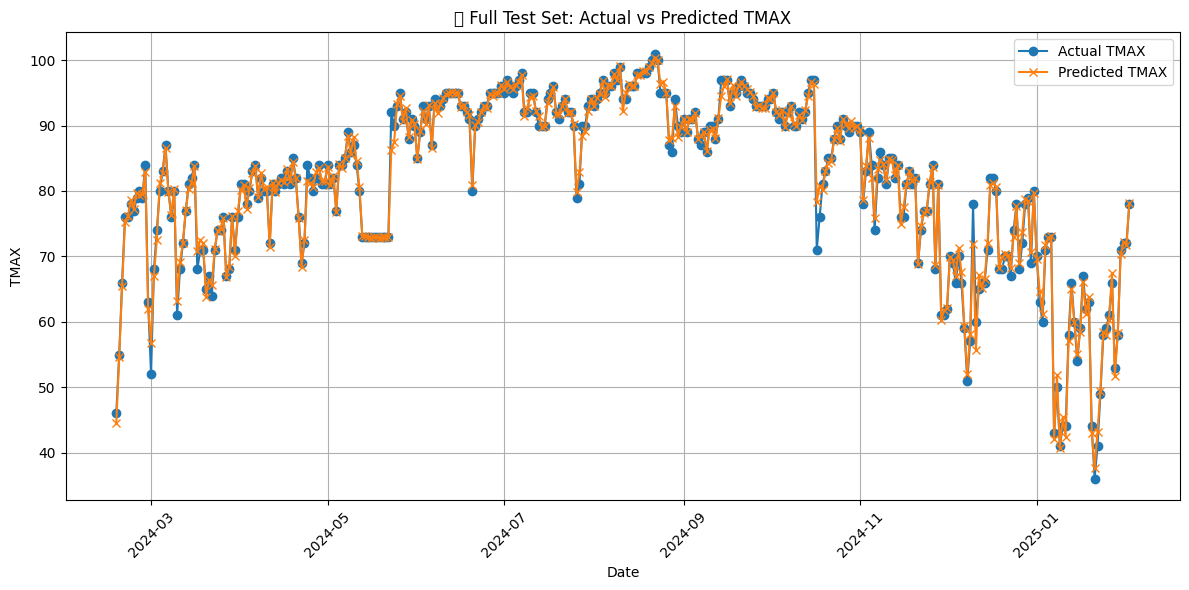

In [ ]:
# Plot
plt.figure(figsize=(12, 6))
plt.plot(output_df['DATE'], output_df['TMAX'], label="Actual TMAX", marker='o')
plt.plot(output_df['DATE'], output_df['Predicted_TMAX'], label="Predicted TMAX", marker='x')
plt.xlabel("Date")
plt.ylabel("TMAX")
plt.title("📈 Full Test Set: Actual vs Predicted TMAX")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### **Dropping the solar radiation**

Fitting 3 folds for each of 20 candidates, totalling 60 fits

✅ Train Set Performance:
R² Score: 0.9979, MAE: 0.4401, MSE: 0.4134, RMSE: 0.6430

📊 Test Set Performance (Full Test Forecast):
R² Score: 0.9934, MAE: 0.6073, MSE: 1.0788, RMSE: 1.0386


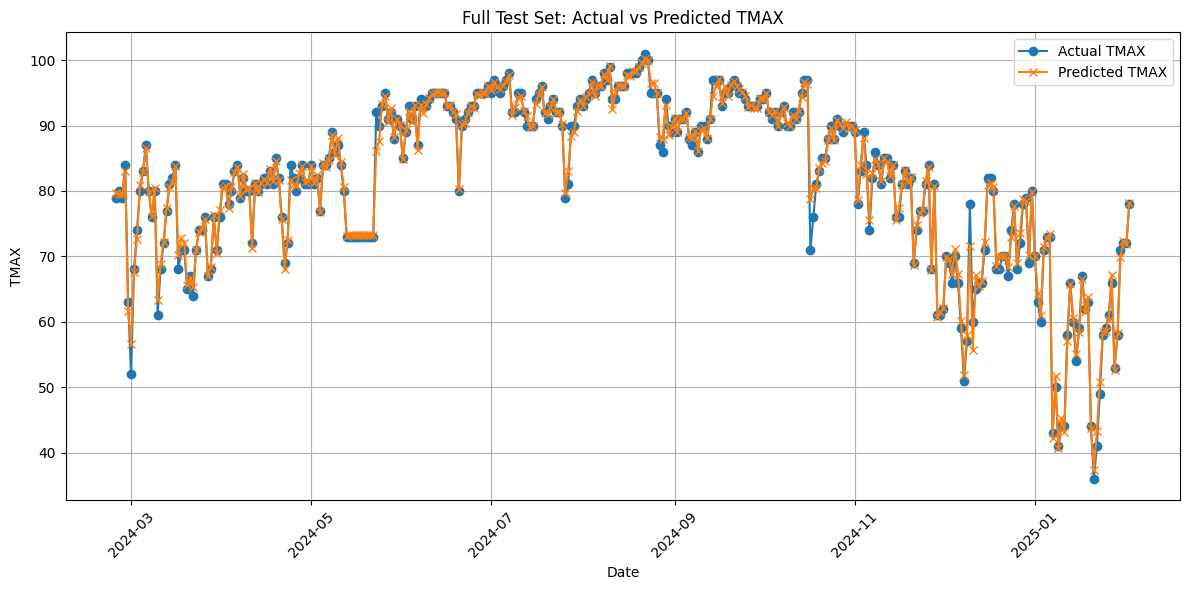

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# # Load datasets
# train_df = pd.read_csv("/content/drive/MyDrive/Project capstone/Train_Brenham.csv")
# test_df = pd.read_csv("/content/drive/MyDrive/Project capstone/Test_Brenham.csv")

# train_df['DATE'] = pd.to_datetime(train_df['DATE'], errors='coerce')
# test_df['DATE'] = pd.to_datetime(test_df['DATE'], errors='coerce')

# Add temporal features
for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

# Add lag and trend features to train
for lag in range(1, 8):
    train_df[f'TMAX_lag_{lag}'] = train_df['TMAX'].shift(lag)
    train_df[f'TMIN_lag_{lag}'] = train_df['TMIN'].shift(lag)
    train_df[f'PRCP_lag_{lag}'] = train_df['PRCP'].shift(lag)
train_df['TMAX_3day_avg'] = train_df['TMAX'].rolling(3).mean()
train_df['PRCP_3day_sum'] = train_df['PRCP'].rolling(3).sum()
train_df['TMAX_trend'] = train_df['TMAX'] - train_df['TMAX'].shift(1)
train_df.dropna(inplace=True)

# Add lag and trend features to test
for lag in range(1, 8):
    test_df[f'TMAX_lag_{lag}'] = test_df['TMAX'].shift(lag)
    test_df[f'TMIN_lag_{lag}'] = test_df['TMIN'].shift(lag)
    test_df[f'PRCP_lag_{lag}'] = test_df['PRCP'].shift(lag)
test_df['TMAX_3day_avg'] = test_df['TMAX'].rolling(3).mean()
test_df['PRCP_3day_sum'] = test_df['PRCP'].rolling(3).sum()
test_df['TMAX_trend'] = test_df['TMAX'] - test_df['TMAX'].shift(1)
test_df.dropna(inplace=True)

# ❌ Dropped 'SOLAR RADIATION' from feature columns
feature_cols = ['TMIN', 'PRCP', 'Month', 'DayOfYear', 'WeekOfYear',
                'DayOfWeek', 'IsWeekend', 'TMAX_3day_avg', 'PRCP_3day_sum', 'TMAX_trend'] + \
               [f'TMAX_lag_{i}' for i in range(1, 8)] + \
               [f'TMIN_lag_{i}' for i in range(1, 8)] + \
               [f'PRCP_lag_{i}' for i in range(1, 8)]

# Split for training and validation
X = train_df[feature_cols]
y = train_df['TMAX']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, shuffle=False)

# Random Forest Hyperparameter Tuning
param_dist = {
    'n_estimators': list(range(100, 400, 50)),
    'max_depth': [3, 5, 7, 9]
}
rf_model = RandomForestRegressor(random_state=42)
search = RandomizedSearchCV(rf_model, param_distributions=param_dist, n_iter=20,
                            scoring='neg_mean_squared_error', cv=3, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
best_model = search.best_estimator_

# Predict on test set
X_test = test_df[feature_cols]
y_test = test_df['TMAX']
test_df['Predicted_TMAX'] = best_model.predict(X_test)

# Save output
output_df = test_df[['DATE', 'TMAX', 'Predicted_TMAX']]
output_df.to_csv("Full_Test_Set_Forecast.csv", index=False)

# ✅ Train Performance
train_preds = best_model.predict(X_train)
train_r2 = r2_score(y_train, train_preds)
train_mae = mean_absolute_error(y_train, train_preds)
train_mse = mean_squared_error(y_train, train_preds)
train_rmse = np.sqrt(train_mse)

print("\n✅ Train Set Performance:")
print(f"R² Score: {train_r2:.4f}, MAE: {train_mae:.4f}, MSE: {train_mse:.4f}, RMSE: {train_rmse:.4f}")

# 📊 Test Performance
r2 = r2_score(y_test, test_df['Predicted_TMAX'])
mae = mean_absolute_error(y_test, test_df['Predicted_TMAX'])
mse = mean_squared_error(y_test, test_df['Predicted_TMAX'])
rmse = np.sqrt(mse)

print("\n📊 Test Set Performance (Full Test Forecast):")
print(f"R² Score: {r2:.4f}, MAE: {mae:.4f}, MSE: {mse:.4f}, RMSE: {rmse:.4f}")

# 📈 Plotting
plt.figure(figsize=(12, 6))
plt.plot(output_df['DATE'], output_df['TMAX'], label="Actual TMAX", marker='o')
plt.plot(output_df['DATE'], output_df['Predicted_TMAX'], label="Predicted TMAX", marker='x')
plt.xlabel("Date")
plt.ylabel("TMAX")
plt.title("Full Test Set: Actual vs Predicted TMAX")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### **Forecasting 7 days TMAX by manual input of TMIN & PRCP**

Fitting 3 folds for each of 20 candidates, totalling 60 fits

🔍 Train Set Performance:
R²: 0.9715
MAE: 1.7083
MSE: 5.4648
RMSE: 2.3377

🧪 Validation Set Performance:
R²: 0.89
MAE: 3.6756
MSE: 25.8932
RMSE: 5.0885

📈 Improved Future 7-Day TMAX Forecast:
        DATE  TMIN  PRCP  Predicted_TMAX
0 2025-02-03    45   0.0       72.540564
1 2025-02-04    65   0.0       77.451446
2 2025-02-05    68   0.0       78.506995
3 2025-02-06    67   0.2       77.690514
4 2025-02-07    54   0.0       75.918020
5 2025-02-08    50   0.0       74.686243
6 2025-02-09    52   0.0       74.862511


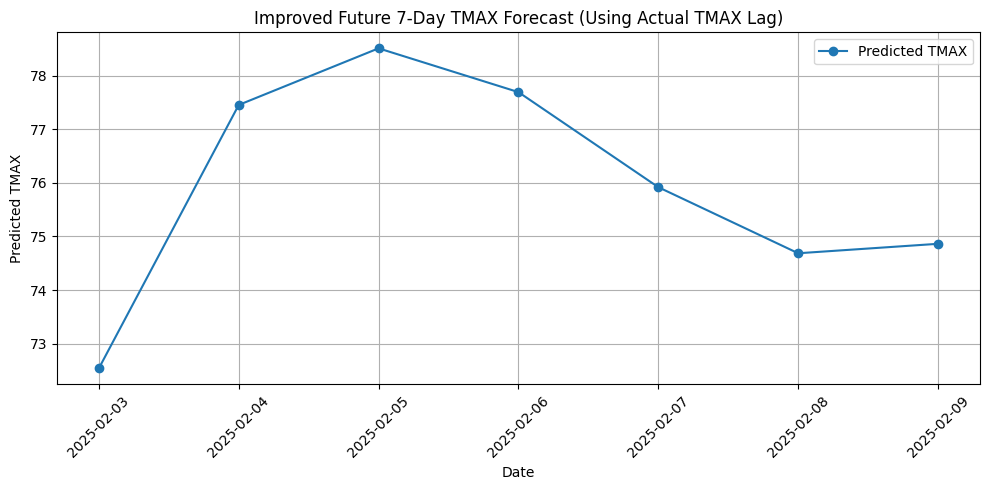

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# # Load datasets
# train_df = pd.read_csv("/content/drive/MyDrive/Project capstone/Train_Brenham.csv")
# test_df = pd.read_csv("/content/drive/MyDrive/Project capstone/Test_Brenham.csv")

# train_df['DATE'] = pd.to_datetime(train_df['DATE'], errors='coerce')
# test_df['DATE'] = pd.to_datetime(test_df['DATE'], errors='coerce')

# Temporal features
for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

# Lag features: Now using 14-day lags
for lag in range(1, 15):
    train_df[f'TMAX_lag_{lag}'] = train_df['TMAX'].shift(lag)
    train_df[f'TMIN_lag_{lag}'] = train_df['TMIN'].shift(lag)
    train_df[f'PRCP_lag_{lag}'] = train_df['PRCP'].shift(lag)
train_df.dropna(inplace=True)

for lag in range(1, 15):
    test_df[f'TMAX_lag_{lag}'] = test_df['TMAX'].shift(lag)
    test_df[f'TMIN_lag_{lag}'] = test_df['TMIN'].shift(lag)
    test_df[f'PRCP_lag_{lag}'] = test_df['PRCP'].shift(lag)
test_df.dropna(inplace=True)

# Features (no solar radiation, no TMAX trend/rolling avg)
feature_cols = ['TMIN', 'PRCP', 'Month', 'DayOfYear', 'WeekOfYear',
                'DayOfWeek', 'IsWeekend'] + \
               [f'TMAX_lag_{i}' for i in range(1, 15)] + \
               [f'TMIN_lag_{i}' for i in range(1, 15)] + \
               [f'PRCP_lag_{i}' for i in range(1, 15)]

# Split train/val
X = train_df[feature_cols]
y = train_df['TMAX']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, shuffle=False)

# Random Forest + Hyperparameter tuning
param_dist = {
    'n_estimators': list(range(100, 400, 50)),
    'max_depth': [5, 7, 9, 11]
}
rf_model = RandomForestRegressor(random_state=42)
search = RandomizedSearchCV(rf_model, param_distributions=param_dist, n_iter=20,
                            scoring='neg_mean_squared_error', cv=3, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
best_model = search.best_estimator_

# ------------------------------
# 📊 Train and Test Performance Evaluation
# ------------------------------

# Predict on training and test sets
train_preds = best_model.predict(X_train)
val_preds = best_model.predict(X_val)

# Train set metrics
print("\n🔍 Train Set Performance:")
print("R²:", round(r2_score(y_train, train_preds), 4))
print("MAE:", round(mean_absolute_error(y_train, train_preds), 4))
print("MSE:", round(mean_squared_error(y_train, train_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train, train_preds)), 4))

# Validation/Test set metrics
print("\n🧪 Validation Set Performance:")
print("R²:", round(r2_score(y_val, val_preds), 4))
print("MAE:", round(mean_absolute_error(y_val, val_preds), 4))
print("MSE:", round(mean_squared_error(y_val, val_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, val_preds)), 4))


# Predict test
X_test = test_df[feature_cols]
test_df['Predicted_TMAX'] = best_model.predict(X_test)

# ✅ FUTURE FORECAST: Use ONLY historical TMAX (not predicted) for lags
start_date = test_df['DATE'].max() + pd.Timedelta(days=1)
future_dates = pd.date_range(start=start_date, periods=7)

# Update these inputs manually if needed
future_input = {
    'DATE': future_dates,
    'TMIN': [45, 65, 68, 67, 54, 50, 52],
    'PRCP': [0.0, 0.0, 0.0, 0.2, 0.0, 0.0, 0.0]
}
future_df = pd.DataFrame(future_input)
future_df['DATE'] = pd.to_datetime(future_df['DATE'])

# Temporal features
future_df['Month'] = future_df['DATE'].dt.month
future_df['DayOfYear'] = future_df['DATE'].dt.dayofyear
future_df['WeekOfYear'] = future_df['DATE'].dt.isocalendar().week.astype(int)
future_df['DayOfWeek'] = future_df['DATE'].dt.weekday
future_df['IsWeekend'] = future_df['DayOfWeek'] >= 5

# Use ONLY actual TMAX from test set for lags
history = test_df.copy()
predictions = []

for i in range(7):
    row = future_df.iloc[i].copy()

    for lag in range(1, 15):
        row[f'TMAX_lag_{lag}'] = history['TMAX'].iloc[-lag]
        row[f'TMIN_lag_{lag}'] = history['TMIN'].iloc[-lag]
        row[f'PRCP_lag_{lag}'] = history['PRCP'].iloc[-lag]

    row_X = row[feature_cols].values.reshape(1, -1)
    row['Predicted_TMAX'] = best_model.predict(row_X)[0]
    predictions.append(row)

    # Append actual TMIN/PRCP, but NOT the predicted TMAX to history
    # (keep using real TMAX from test set)
    row['TMAX'] = row['Predicted_TMAX']  # Only to keep format
    history = pd.concat([history, pd.DataFrame([row])], ignore_index=True)

# Compile forecast output
future_forecast_df = pd.DataFrame(predictions)
future_forecast_df = future_forecast_df[['DATE', 'TMIN', 'PRCP', 'Predicted_TMAX']]
future_forecast_df.to_csv("Improved_7_Day_TMAX_Forecast.csv", index=False)

# 📊 Print future forecast
print("\n📈 Improved Future 7-Day TMAX Forecast:")
print(future_forecast_df)

# 📈 Plot forecast
plt.figure(figsize=(10, 5))
plt.plot(future_forecast_df['DATE'], future_forecast_df['Predicted_TMAX'], marker='o', label="Predicted TMAX")
plt.title("Improved Future 7-Day TMAX Forecast (Using Actual TMAX Lag)")
plt.xlabel("Date")
plt.ylabel("Predicted TMAX")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Fitting 3 folds for each of 20 candidates, totalling 60 fits

🔍 Train Set Performance:
R²: 0.972
MAE: 1.6929
MSE: 5.3427
RMSE: 2.3114

🧪 Validation Set Performance:
R²: 0.8871
MAE: 3.7391
MSE: 26.6408
RMSE: 5.1615

🧪 Test Set Performance:
R²: 0.8828
MAE: 3.2113
MSE: 19.4569
RMSE: 4.411

📈 Improved Future 7-Day TMAX Forecast:
        DATE  TMIN  PRCP  Predicted_TMAX
0 2025-02-03    45   0.0       72.627301
1 2025-02-04    65   0.0       77.270787
2 2025-02-05    68   0.0       78.121200
3 2025-02-06    67   0.2       78.052623
4 2025-02-07    54   0.0       76.080750
5 2025-02-08    50   0.0       75.283480
6 2025-02-09    52   0.0       74.871065


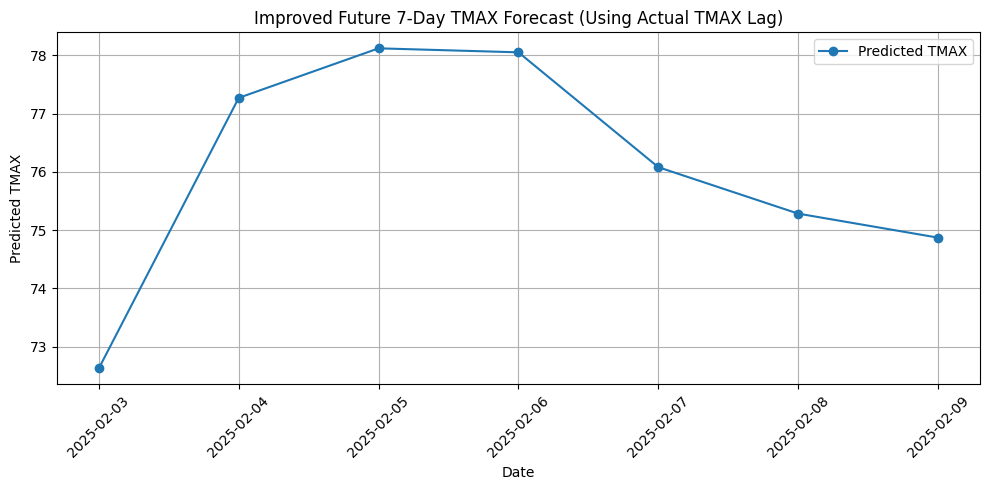

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# # -------------------------
# # 📦 Load datasets
# # -------------------------
# train_df = pd.read_csv("/content/drive/MyDrive/Project capstone/Train_Brenham.csv")
# test_df = pd.read_csv("/content/drive/MyDrive/Project capstone/Test_Brenham.csv")

# train_df['DATE'] = pd.to_datetime(train_df['DATE'], errors='coerce')
# test_df['DATE'] = pd.to_datetime(test_df['DATE'], errors='coerce')

# -------------------------
# 🧠 Feature Engineering
# -------------------------
for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

# Lag features
for lag in range(1, 15):
    for col in ['TMAX', 'TMIN', 'PRCP']:
        train_df[f'{col}_lag_{lag}'] = train_df[col].shift(lag)
train_df.dropna(inplace=True)

for lag in range(1, 15):
    for col in ['TMAX', 'TMIN', 'PRCP']:
        test_df[f'{col}_lag_{lag}'] = test_df[col].shift(lag)
test_df.dropna(inplace=True)

# Feature columns
feature_cols = ['TMIN', 'PRCP', 'Month', 'DayOfYear', 'WeekOfYear',
                'DayOfWeek', 'IsWeekend'] + \
               [f'TMAX_lag_{i}' for i in range(1, 15)] + \
               [f'TMIN_lag_{i}' for i in range(1, 15)] + \
               [f'PRCP_lag_{i}' for i in range(1, 15)]

# -------------------------
# 🔀 Train / Validation Split
# -------------------------
X = train_df[feature_cols]
y = train_df['TMAX']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, shuffle=False)

# -------------------------
# 🌲 Random Forest + Tuning
# -------------------------
param_dist = {
    'n_estimators': list(range(100, 400, 50)),
    'max_depth': [5, 7, 9, 11]
}
rf_model = RandomForestRegressor(random_state=42)
search = RandomizedSearchCV(rf_model, param_distributions=param_dist, n_iter=20,
                            scoring='neg_mean_squared_error', cv=3, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
best_model = search.best_estimator_

# -------------------------
# 📊 Train and Validation Performance
# -------------------------
train_preds = best_model.predict(X_train)
val_preds = best_model.predict(X_val)

print("\n🔍 Train Set Performance:")
print("R²:", round(r2_score(y_train, train_preds), 4))
print("MAE:", round(mean_absolute_error(y_train, train_preds), 4))
print("MSE:", round(mean_squared_error(y_train, train_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train, train_preds)), 4))

print("\n🧪 Validation Set Performance:")
print("R²:", round(r2_score(y_val, val_preds), 4))
print("MAE:", round(mean_absolute_error(y_val, val_preds), 4))
print("MSE:", round(mean_squared_error(y_val, val_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, val_preds)), 4))

# -------------------------
# 🧪 Test Set Evaluation
# -------------------------
X_test = test_df[feature_cols]
test_df['Predicted_TMAX'] = best_model.predict(X_test)

y_test = test_df['TMAX']
test_preds = test_df['Predicted_TMAX']

print("\n🧪 Test Set Performance:")
print("R²:", round(r2_score(y_test, test_preds), 4))
print("MAE:", round(mean_absolute_error(y_test, test_preds), 4))
print("MSE:", round(mean_squared_error(y_test, test_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, test_preds)), 4))

# -------------------------
# ⏭️ 7-Day Future Forecast
# -------------------------
start_date = test_df['DATE'].max() + pd.Timedelta(days=1)
future_dates = pd.date_range(start=start_date, periods=7)

# Manually update with known inputs
future_input = {
    'DATE': future_dates,
    'TMIN': [45, 65, 68, 67, 54, 50, 52],
    'PRCP': [0.0, 0.0, 0.0, 0.2, 0.0, 0.0, 0.0]
}
future_df = pd.DataFrame(future_input)
future_df['DATE'] = pd.to_datetime(future_df['DATE'])

# Temporal features
future_df['Month'] = future_df['DATE'].dt.month
future_df['DayOfYear'] = future_df['DATE'].dt.dayofyear
future_df['WeekOfYear'] = future_df['DATE'].dt.isocalendar().week.astype(int)
future_df['DayOfWeek'] = future_df['DATE'].dt.weekday
future_df['IsWeekend'] = future_df['DayOfWeek'] >= 5

# Generate future forecast step-by-step using true historical lags
history = test_df.copy()
predictions = []

for i in range(7):
    row = future_df.iloc[i].copy()

    for lag in range(1, 15):
        row[f'TMAX_lag_{lag}'] = history['TMAX'].iloc[-lag]
        row[f'TMIN_lag_{lag}'] = history['TMIN'].iloc[-lag]
        row[f'PRCP_lag_{lag}'] = history['PRCP'].iloc[-lag]

    row_X = row[feature_cols].values.reshape(1, -1)
    row['Predicted_TMAX'] = best_model.predict(row_X)[0]
    predictions.append(row)

    row['TMAX'] = row['Predicted_TMAX']  # only for history format
    history = pd.concat([history, pd.DataFrame([row])], ignore_index=True)

# Forecast DataFrame
future_forecast_df = pd.DataFrame(predictions)
future_forecast_df = future_forecast_df[['DATE', 'TMIN', 'PRCP', 'Predicted_TMAX']]
future_forecast_df.to_csv("Improved_7_Day_TMAX_Forecast.csv", index=False)

# -------------------------
# 📈 Plot Future Forecast
# -------------------------
print("\n📈 Improved Future 7-Day TMAX Forecast:")
print(future_forecast_df)

plt.figure(figsize=(10, 5))
plt.plot(future_forecast_df['DATE'], future_forecast_df['Predicted_TMAX'], marker='o', label="Predicted TMAX")
plt.title("Improved Future 7-Day TMAX Forecast (Using Actual TMAX Lag)")
plt.xlabel("Date")
plt.ylabel("Predicted TMAX")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



### **RandomForest - Predicting TMIN & PRCP and using those to predict TMAX**


🔍 TMAX Model — Train Set Performance:
R²: 0.9989
MAE: 0.2493
MSE: 0.213
RMSE: 0.4615

🧪 TMAX Model — Test Set Performance:
R²: 0.995
MAE: 0.4989
MSE: 0.8369
RMSE: 0.9148
        DATE  Predicted_TMAX
0 2025-02-03       80.779778
1 2025-02-04       80.069738
2 2025-02-05       79.168269
3 2025-02-06       78.480769
4 2025-02-07       78.304857
5 2025-02-08       78.816584
6 2025-02-09       79.554060


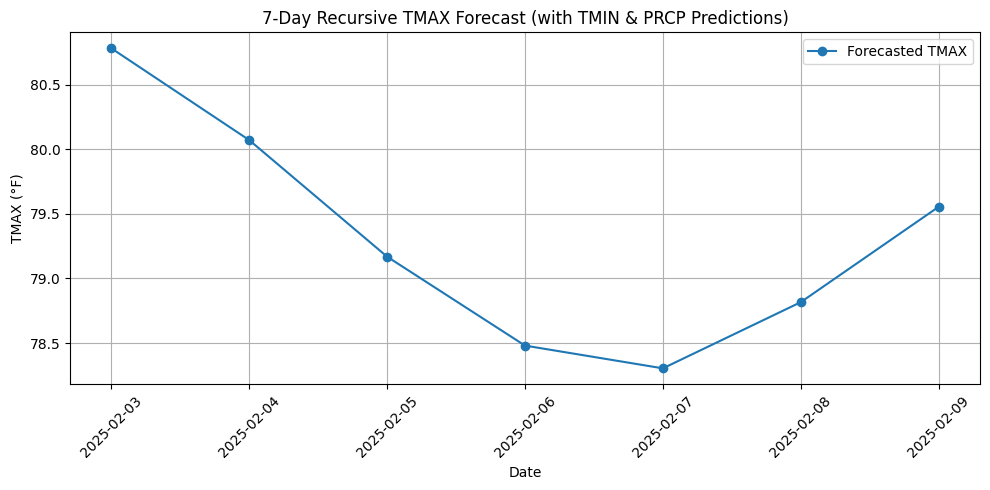

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt



for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

for lag in range(1, 8):
    for df in [train_df, test_df]:
        df[f'TMAX_lag_{lag}'] = df['TMAX'].shift(lag)
        df[f'TMIN_lag_{lag}'] = df['TMIN'].shift(lag)
        df[f'PRCP_lag_{lag}'] = df['PRCP'].shift(lag)

for df in [train_df, test_df]:
    df['TMAX_3day_avg'] = df['TMAX'].rolling(3).mean()
    df['PRCP_3day_sum'] = df['PRCP'].rolling(3).sum()
    df['TMAX_trend'] = df['TMAX'] - df['TMAX'].shift(1)

train_df.dropna(inplace=True)
test_df.dropna(inplace=True)

# ------------------------------
# 🎯 Define Features
# ------------------------------
base_features = ['Month', 'DayOfYear', 'WeekOfYear', 'DayOfWeek', 'IsWeekend']
tmin_features = base_features + [f'TMIN_lag_{i}' for i in range(1, 8)]
prcp_features = base_features + [f'PRCP_lag_{i}' for i in range(1, 8)]
tmax_features = ['TMIN', 'PRCP', 'SOLAR RADIATION', 'TMAX_3day_avg', 'PRCP_3day_sum', 'TMAX_trend'] + \
                base_features + [f'TMAX_lag_{i}' for i in range(1, 8)] + \
                [f'TMIN_lag_{i}' for i in range(1, 8)] + [f'PRCP_lag_{i}' for i in range(1, 8)]

# ------------------------------
# 🔧 Model Training
# ------------------------------
def train_rf(X, y):
    param_dist = {
        'n_estimators': list(range(100, 500, 50)),
        'max_depth': [5, 10, 15],
        'min_samples_split': [2, 5, 10]
    }
    model = RandomForestRegressor(random_state=42)
    search = RandomizedSearchCV(model, param_distributions=param_dist, n_iter=10,
                                scoring='neg_mean_squared_error', cv=3, n_jobs=-1)
    search.fit(X, y)
    return search.best_estimator_

tmin_model = train_rf(train_df[tmin_features], train_df['TMIN'])
prcp_model = train_rf(train_df[prcp_features], train_df['PRCP'])
tmax_model = train_rf(train_df[tmax_features], train_df['TMAX'])

# ------------------------------
# 📊 Evaluate Performance on Existing Train and Test Sets
# ------------------------------

# Predict on train_df and test_df
train_preds = tmax_model.predict(train_df[tmax_features])
test_preds = tmax_model.predict(test_df[tmax_features])

# Ground truth
y_train_true = train_df['TMAX']
y_test_true = test_df['TMAX']

# Train set performance
print("\n🔍 TMAX Model — Train Set Performance:")
print("R²:", round(r2_score(y_train_true, train_preds), 4))
print("MAE:", round(mean_absolute_error(y_train_true, train_preds), 4))
print("MSE:", round(mean_squared_error(y_train_true, train_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train_true, train_preds)), 4))

# Test set performance
print("\n🧪 TMAX Model — Test Set Performance:")
print("R²:", round(r2_score(y_test_true, test_preds), 4))
print("MAE:", round(mean_absolute_error(y_test_true, test_preds), 4))
print("MSE:", round(mean_squared_error(y_test_true, test_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_true, test_preds)), 4))


# ------------------------------
# 🔮 7-Day Recursive Forecast
# ------------------------------
forecast_days = 7
forecast_dates = pd.date_range(start=test_df['DATE'].max() + pd.Timedelta(days=1), periods=forecast_days)
forecast_records = []
lags_df = test_df.tail(7).copy()
last_known = test_df.tail(30)

for i, date in enumerate(forecast_dates):
    base_row = {
        'Month': date.month,
        'DayOfYear': date.dayofyear,
        'WeekOfYear': date.isocalendar().week,
        'DayOfWeek': date.weekday(),
        'IsWeekend': int(date.weekday() >= 5)
    }

    for lag in range(1, 8):
        base_row[f'TMIN_lag_{lag}'] = lags_df['TMIN'].values[-lag]
        base_row[f'PRCP_lag_{lag}'] = lags_df['PRCP'].values[-lag]
        base_row[f'TMAX_lag_{lag}'] = lags_df['TMAX'].values[-lag]

    tmin_pred = tmin_model.predict(pd.DataFrame([base_row])[tmin_features])[0]
    prcp_pred = prcp_model.predict(pd.DataFrame([base_row])[prcp_features])[0]
    solar_radiation = last_known['SOLAR RADIATION'].mean()

    tmax_row = base_row.copy()
    tmax_row.update({
        'TMIN': tmin_pred,
        'PRCP': prcp_pred,
        'SOLAR RADIATION': solar_radiation,
        'TMAX_3day_avg': lags_df['TMAX'].tail(3).mean(),
        'PRCP_3day_sum': lags_df['PRCP'].tail(3).sum(),
        'TMAX_trend': lags_df['TMAX'].values[-1] - lags_df['TMAX'].values[-2]
    })

    tmax_pred = tmax_model.predict(pd.DataFrame([tmax_row])[tmax_features])[0]
    forecast_records.append({'DATE': date, 'Predicted_TMAX': tmax_pred})


    new_row = {'TMAX': tmax_pred, 'TMIN': tmin_pred, 'PRCP': prcp_pred}
    lags_df = pd.concat([lags_df, pd.DataFrame([new_row])], ignore_index=True).tail(7)

# ------------------------------
# 💾 Results
# ------------------------------
forecast_df = pd.DataFrame(forecast_records)
print(forecast_df)

# 📈 Plot
plt.figure(figsize=(10, 5))
plt.plot(forecast_df['DATE'], forecast_df['Predicted_TMAX'], marker='o', label='Forecasted TMAX')
plt.title("7-Day Recursive TMAX Forecast (with TMIN & PRCP Predictions)")
plt.xlabel("Date")
plt.ylabel("TMAX (°F)")
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## **XGBoost Regressor**

### **Manual input of TMIN & PRCP**

Fitting 3 folds for each of 20 candidates, totalling 60 fits

🔍 Train Set Performance:
R²: 0.9349
MAE: 2.5225
MSE: 12.6647
RMSE: 3.5588

🧪 Test Set Performance:
R²: 0.8931
MAE: 3.0649
MSE: 19.0396
RMSE: 4.3634

📈 Improved Future 7-Day TMAX Forecast (XGBoost):
        DATE  TMIN  PRCP  Predicted_TMAX
0 2025-02-03    45   0.0       70.919991
1 2025-02-04    65   0.0       80.793594
2 2025-02-05    68   0.0       81.889580
3 2025-02-06    67   0.2       79.753197
4 2025-02-07    54   0.0       74.262802
5 2025-02-08    50   0.0       72.034706
6 2025-02-09    52   0.0       75.624458


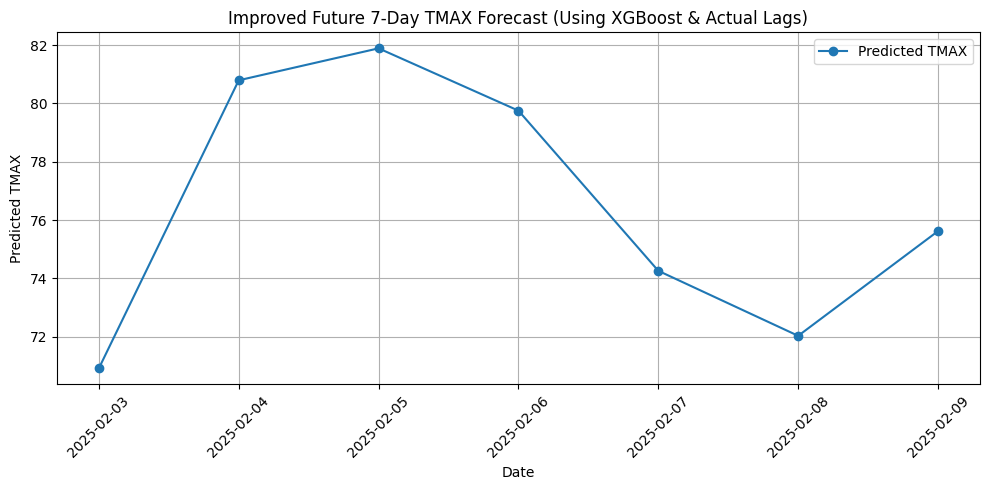

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
import matplotlib.pyplot as plt



# Temporal features
for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

# Lag features: 14-day lags
for lag in range(1, 15):
    train_df[f'TMAX_lag_{lag}'] = train_df['TMAX'].shift(lag)
    train_df[f'TMIN_lag_{lag}'] = train_df['TMIN'].shift(lag)
    train_df[f'PRCP_lag_{lag}'] = train_df['PRCP'].shift(lag)
train_df.dropna(inplace=True)

for lag in range(1, 15):
    test_df[f'TMAX_lag_{lag}'] = test_df['TMAX'].shift(lag)
    test_df[f'TMIN_lag_{lag}'] = test_df['TMIN'].shift(lag)
    test_df[f'PRCP_lag_{lag}'] = test_df['PRCP'].shift(lag)
test_df.dropna(inplace=True)

# Features (no solar radiation, no TMAX trend/rolling avg)
feature_cols = ['TMIN', 'PRCP', 'Month', 'DayOfYear', 'WeekOfYear',
                'DayOfWeek', 'IsWeekend'] + \
               [f'TMAX_lag_{i}' for i in range(1, 15)] + \
               [f'TMIN_lag_{i}' for i in range(1, 15)] + \
               [f'PRCP_lag_{i}' for i in range(1, 15)]

# Split train/val
X = train_df[feature_cols]
y = train_df['TMAX']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, shuffle=False)

# XGBoost + Hyperparameter tuning
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}
xgb_model = XGBRegressor(random_state=42, objective='reg:squarederror', n_jobs=-1, verbosity=0)
search = RandomizedSearchCV(xgb_model, param_distributions=param_dist, n_iter=20,
                            scoring='neg_mean_squared_error', cv=3, n_jobs=-1, verbose=1)
search.fit(X_train, y_train)
best_model = search.best_estimator_

# ------------------------------
# 📊 Model Performance Metrics
# ------------------------------

# Predict on training and test datasets
train_preds = best_model.predict(train_df[feature_cols])
test_preds = best_model.predict(test_df[feature_cols])

# True labels
y_train_true = train_df['TMAX']
y_test_true = test_df['TMAX']

# Train Set Metrics
print("\n🔍 Train Set Performance:")
print("R²:", round(r2_score(y_train_true, train_preds), 4))
print("MAE:", round(mean_absolute_error(y_train_true, train_preds), 4))
print("MSE:", round(mean_squared_error(y_train_true, train_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train_true, train_preds)), 4))

# Test Set Metrics
print("\n🧪 Test Set Performance:")
print("R²:", round(r2_score(y_test_true, test_preds), 4))
print("MAE:", round(mean_absolute_error(y_test_true, test_preds), 4))
print("MSE:", round(mean_squared_error(y_test_true, test_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_true, test_preds)), 4))


# Predict test
X_test = test_df[feature_cols]
test_df['Predicted_TMAX'] = best_model.predict(X_test)

# ✅ FUTURE FORECAST: Use ONLY historical TMAX (not predicted) for lags
start_date = test_df['DATE'].max() + pd.Timedelta(days=1)
future_dates = pd.date_range(start=start_date, periods=7)

# Update these inputs manually if needed
future_input = {
    'DATE': future_dates,
    'TMIN': [45, 65, 68, 67, 54, 50, 52],
    'PRCP': [0.0, 0.0, 0.0, 0.2, 0.0, 0.0, 0.0]
}
future_df = pd.DataFrame(future_input)
future_df['DATE'] = pd.to_datetime(future_df['DATE'])

# Temporal features
future_df['Month'] = future_df['DATE'].dt.month
future_df['DayOfYear'] = future_df['DATE'].dt.dayofyear
future_df['WeekOfYear'] = future_df['DATE'].dt.isocalendar().week.astype(int)
future_df['DayOfWeek'] = future_df['DATE'].dt.weekday
future_df['IsWeekend'] = future_df['DayOfWeek'] >= 5

# Use ONLY actual TMAX from test set for lags
history = test_df.copy()
predictions = []

for i in range(7):
    row = future_df.iloc[i].copy()

    for lag in range(1, 15):
        row[f'TMAX_lag_{lag}'] = history['TMAX'].iloc[-lag]
        row[f'TMIN_lag_{lag}'] = history['TMIN'].iloc[-lag]
        row[f'PRCP_lag_{lag}'] = history['PRCP'].iloc[-lag]

    row_X = row[feature_cols].values.reshape(1, -1)
    row['Predicted_TMAX'] = best_model.predict(row_X)[0]
    predictions.append(row)

    # Append actual TMIN/PRCP, but NOT the predicted TMAX to history
    row['TMAX'] = row['Predicted_TMAX']  # Only to keep format
    history = pd.concat([history, pd.DataFrame([row])], ignore_index=True)

# Compile forecast output
future_forecast_df = pd.DataFrame(predictions)
future_forecast_df = future_forecast_df[['DATE', 'TMIN', 'PRCP', 'Predicted_TMAX']]
future_forecast_df.to_csv("Improved_7_Day_TMAX_Forecast_XGBoost.csv", index=False)

# 📊 Print future forecast
print("\n📈 Improved Future 7-Day TMAX Forecast (XGBoost):")
print(future_forecast_df)

# 📈 Plot forecast
plt.figure(figsize=(10, 5))
plt.plot(future_forecast_df['DATE'], future_forecast_df['Predicted_TMAX'], marker='o', label="Predicted TMAX")
plt.title("Improved Future 7-Day TMAX Forecast (Using XGBoost & Actual Lags)")
plt.xlabel("Date")
plt.ylabel("Predicted TMAX")
plt.xticks(rotation=45)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


### **Predicting TMIN, PRCP and using those values to predict TMAX recursively**


🔍 TMAX Model — Train Set Performance:
R²: 0.9992
MAE: 0.3091
MSE: 0.1644
RMSE: 0.4054

🧪 TMAX Model — Test Set Performance:
R²: 0.9972
MAE: 0.4261
MSE: 0.4722
RMSE: 0.6872
        DATE  Predicted_TMAX
0 2025-02-03       79.198959
1 2025-02-04       76.840797
2 2025-02-05       75.183189
3 2025-02-06       75.732132
4 2025-02-07       75.713997
5 2025-02-08       74.093018
6 2025-02-09       72.911125


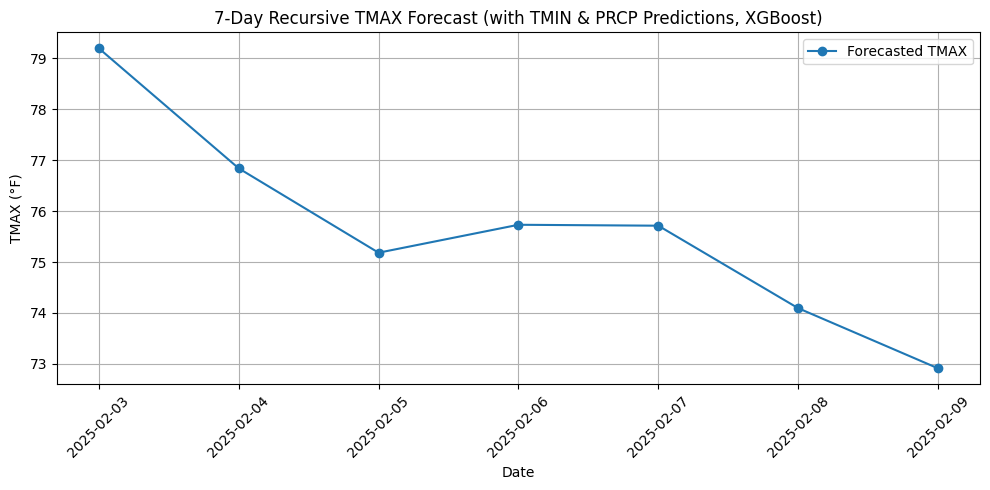

In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt


for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

for lag in range(1, 8):
    for df in [train_df, test_df]:
        df[f'TMAX_lag_{lag}'] = df['TMAX'].shift(lag)
        df[f'TMIN_lag_{lag}'] = df['TMIN'].shift(lag)
        df[f'PRCP_lag_{lag}'] = df['PRCP'].shift(lag)

for df in [train_df, test_df]:
    df['TMAX_3day_avg'] = df['TMAX'].rolling(3).mean()
    df['PRCP_3day_sum'] = df['PRCP'].rolling(3).sum()
    df['TMAX_trend'] = df['TMAX'] - df['TMAX'].shift(1)

train_df.dropna(inplace=True)
test_df.dropna(inplace=True)

# ------------------------------
# 🎯 Define Features
# ------------------------------
base_features = ['Month', 'DayOfYear', 'WeekOfYear', 'DayOfWeek', 'IsWeekend']
tmin_features = base_features + [f'TMIN_lag_{i}' for i in range(1, 8)]
prcp_features = base_features + [f'PRCP_lag_{i}' for i in range(1, 8)]
tmax_features = ['TMIN', 'PRCP', 'SOLAR RADIATION', 'TMAX_3day_avg', 'PRCP_3day_sum', 'TMAX_trend'] + \
                base_features + [f'TMAX_lag_{i}' for i in range(1, 8)] + \
                [f'TMIN_lag_{i}' for i in range(1, 8)] + [f'PRCP_lag_{i}' for i in range(1, 8)]

# ------------------------------
# 🔧 Model Training (XGBoost)
# ------------------------------
def train_xgb(X, y):
    param_dist = {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.7, 0.9, 1.0],
        'colsample_bytree': [0.7, 0.9, 1.0]
    }
    model = XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=-1, verbosity=0)
    search = RandomizedSearchCV(model, param_distributions=param_dist, n_iter=10,
                                scoring='neg_mean_squared_error', cv=3, n_jobs=-1)
    search.fit(X, y)
    return search.best_estimator_

tmin_model = train_xgb(train_df[tmin_features], train_df['TMIN'])
prcp_model = train_xgb(train_df[prcp_features], train_df['PRCP'])
tmax_model = train_xgb(train_df[tmax_features], train_df['TMAX'])

# ------------------------------
# 📊 TMAX Model Performance Metrics
# ------------------------------

# Predict on train and test sets
train_preds = tmax_model.predict(train_df[tmax_features])
test_preds = tmax_model.predict(test_df[tmax_features])

# Ground truth values
y_train_true = train_df['TMAX']
y_test_true = test_df['TMAX']

# Train Set Metrics
print("\n🔍 TMAX Model — Train Set Performance:")
print("R²:", round(r2_score(y_train_true, train_preds), 4))
print("MAE:", round(mean_absolute_error(y_train_true, train_preds), 4))
print("MSE:", round(mean_squared_error(y_train_true, train_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train_true, train_preds)), 4))

# Test Set Metrics
print("\n🧪 TMAX Model — Test Set Performance:")
print("R²:", round(r2_score(y_test_true, test_preds), 4))
print("MAE:", round(mean_absolute_error(y_test_true, test_preds), 4))
print("MSE:", round(mean_squared_error(y_test_true, test_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_true, test_preds)), 4))


# ------------------------------
# 🔮 7-Day Recursive Forecast
# ------------------------------
forecast_days = 7
forecast_dates = pd.date_range(start=test_df['DATE'].max() + pd.Timedelta(days=1), periods=forecast_days)
forecast_records = []
lags_df = test_df.tail(7).copy()
last_known = test_df.tail(30)

for i, date in enumerate(forecast_dates):
    base_row = {
        'Month': date.month,
        'DayOfYear': date.dayofyear,
        'WeekOfYear': date.isocalendar().week,
        'DayOfWeek': date.weekday(),
        'IsWeekend': int(date.weekday() >= 5)
    }

    for lag in range(1, 8):
        base_row[f'TMIN_lag_{lag}'] = lags_df['TMIN'].values[-lag]
        base_row[f'PRCP_lag_{lag}'] = lags_df['PRCP'].values[-lag]
        base_row[f'TMAX_lag_{lag}'] = lags_df['TMAX'].values[-lag]

    tmin_pred = tmin_model.predict(pd.DataFrame([base_row])[tmin_features])[0]
    prcp_pred = prcp_model.predict(pd.DataFrame([base_row])[prcp_features])[0]
    solar_radiation = last_known['SOLAR RADIATION'].mean()

    tmax_row = base_row.copy()
    tmax_row.update({
        'TMIN': tmin_pred,
        'PRCP': prcp_pred,
        'SOLAR RADIATION': solar_radiation,
        'TMAX_3day_avg': lags_df['TMAX'].tail(3).mean(),
        'PRCP_3day_sum': lags_df['PRCP'].tail(3).sum(),
        'TMAX_trend': lags_df['TMAX'].values[-1] - lags_df['TMAX'].values[-2]
    })

    tmax_pred = tmax_model.predict(pd.DataFrame([tmax_row])[tmax_features])[0]
    forecast_records.append({'DATE': date, 'Predicted_TMAX': tmax_pred})

    new_row = {'TMAX': tmax_pred, 'TMIN': tmin_pred, 'PRCP': prcp_pred}
    lags_df = pd.concat([lags_df, pd.DataFrame([new_row])], ignore_index=True).tail(7)

# ------------------------------
# 💾 Results
# ------------------------------
forecast_df = pd.DataFrame(forecast_records)
print(forecast_df)

# 📈 Plot
plt.figure(figsize=(10, 5))
plt.plot(forecast_df['DATE'], forecast_df['Predicted_TMAX'], marker='o', label='Forecasted TMAX')
plt.title("7-Day Recursive TMAX Forecast (with TMIN & PRCP Predictions, XGBoost)")
plt.xlabel("Date")
plt.ylabel("TMAX (°F)")
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
df = pd.read_csv("imputed_all_stations_data.csv")

# Filter rows where station is "USW00003904"
brenham_df = df[df['STATION'] == "USW00003904"]

brenham_df.head()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,PRCP,TMAX,TMIN,COUNTY,SOLAR RADIATION
0,USW00003904,"COLLEGE STATION EASTERWOOD FIELD, TX US",30.5912,-96.36309,96.0,1/1/2015,0.49,42,37,Brazos County,2.71
1,USW00003904,"COLLEGE STATION EASTERWOOD FIELD, TX US",30.5912,-96.36309,96.0,1/2/2015,0.20,45,41,Brazos County,2.73
2,USW00003904,"COLLEGE STATION EASTERWOOD FIELD, TX US",30.5912,-96.36309,96.0,1/3/2015,1.05,50,39,Brazos County,7.59
3,USW00003904,"COLLEGE STATION EASTERWOOD FIELD, TX US",30.5912,-96.36309,96.0,1/4/2015,0.00,49,33,Brazos County,14.06
4,USW00003904,"COLLEGE STATION EASTERWOOD FIELD, TX US",30.5912,-96.36309,96.0,1/5/2015,0.00,51,29,Brazos County,14.96


In [ ]:
# Ensure the DATE column is datetime type
brenham_df['DATE'] = pd.to_datetime(brenham_df['DATE'])

# Sort by DATE to maintain time order
brenham_df = brenham_df.sort_values(by='DATE').reset_index(drop=True)

# Calculate split index
split_index = int(len(brenham_df) * 0.9)

# Split into train and test
train_df = brenham_df.iloc[:split_index].copy()
test_df = brenham_df.iloc[split_index:].copy()



🔍 TMAX Model — Train Set Performance:
R²: 1.0
MAE: 0.0783
MSE: 0.0106
RMSE: 0.1032

🧪 TMAX Model — Test Set Performance:
R²: 0.9962
MAE: 0.4468
MSE: 0.6477
RMSE: 0.8048
        DATE  Predicted_TMAX
0 2025-02-03       80.047302
1 2025-02-04       79.017029
2 2025-02-05       77.519073
3 2025-02-06       75.836037
4 2025-02-07       73.759644
5 2025-02-08       71.397087
6 2025-02-09       70.152252


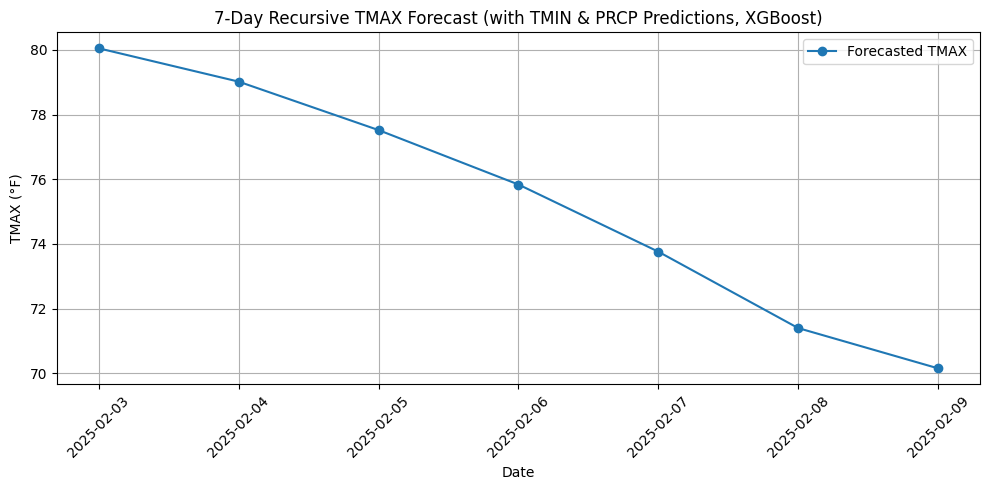

In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt


for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

for lag in range(1, 8):
    for df in [train_df, test_df]:
        df[f'TMAX_lag_{lag}'] = df['TMAX'].shift(lag)
        df[f'TMIN_lag_{lag}'] = df['TMIN'].shift(lag)
        df[f'PRCP_lag_{lag}'] = df['PRCP'].shift(lag)

for df in [train_df, test_df]:
    df['TMAX_3day_avg'] = df['TMAX'].rolling(3).mean()
    df['PRCP_3day_sum'] = df['PRCP'].rolling(3).sum()
    df['TMAX_trend'] = df['TMAX'] - df['TMAX'].shift(1)

train_df.dropna(inplace=True)
test_df.dropna(inplace=True)

# ------------------------------
# 🎯 Define Features
# ------------------------------
base_features = ['Month', 'DayOfYear', 'WeekOfYear', 'DayOfWeek', 'IsWeekend']
tmin_features = base_features + [f'TMIN_lag_{i}' for i in range(1, 8)]
prcp_features = base_features + [f'PRCP_lag_{i}' for i in range(1, 8)]
tmax_features = ['TMIN', 'PRCP', 'SOLAR RADIATION', 'TMAX_3day_avg', 'PRCP_3day_sum', 'TMAX_trend'] + \
                base_features + [f'TMAX_lag_{i}' for i in range(1, 8)] + \
                [f'TMIN_lag_{i}' for i in range(1, 8)] + [f'PRCP_lag_{i}' for i in range(1, 8)]

# ------------------------------
# 🔧 Model Training (XGBoost)
# ------------------------------
def train_xgb(X, y):
    param_dist = {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.7, 0.9, 1.0],
        'colsample_bytree': [0.7, 0.9, 1.0]
    }
    model = XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=-1, verbosity=0)
    search = RandomizedSearchCV(model, param_distributions=param_dist, n_iter=10,
                                scoring='neg_mean_squared_error', cv=3, n_jobs=-1)
    search.fit(X, y)
    return search.best_estimator_

tmin_model = train_xgb(train_df[tmin_features], train_df['TMIN'])
prcp_model = train_xgb(train_df[prcp_features], train_df['PRCP'])
tmax_model = train_xgb(train_df[tmax_features], train_df['TMAX'])

# ------------------------------
# 📊 TMAX Model Performance Metrics
# ------------------------------

# Predict on train and test sets
train_preds = tmax_model.predict(train_df[tmax_features])
test_preds = tmax_model.predict(test_df[tmax_features])

# Ground truth values
y_train_true = train_df['TMAX']
y_test_true = test_df['TMAX']

# Train Set Metrics
print("\n🔍 TMAX Model — Train Set Performance:")
print("R²:", round(r2_score(y_train_true, train_preds), 4))
print("MAE:", round(mean_absolute_error(y_train_true, train_preds), 4))
print("MSE:", round(mean_squared_error(y_train_true, train_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_train_true, train_preds)), 4))

# Test Set Metrics
print("\n🧪 TMAX Model — Test Set Performance:")
print("R²:", round(r2_score(y_test_true, test_preds), 4))
print("MAE:", round(mean_absolute_error(y_test_true, test_preds), 4))
print("MSE:", round(mean_squared_error(y_test_true, test_preds), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_true, test_preds)), 4))


# ------------------------------
# 🔮 7-Day Recursive Forecast
# ------------------------------
forecast_days = 7
forecast_dates = pd.date_range(start=test_df['DATE'].max() + pd.Timedelta(days=1), periods=forecast_days)
forecast_records = []
lags_df = test_df.tail(7).copy()
last_known = test_df.tail(30)

for i, date in enumerate(forecast_dates):
    base_row = {
        'Month': date.month,
        'DayOfYear': date.dayofyear,
        'WeekOfYear': date.isocalendar().week,
        'DayOfWeek': date.weekday(),
        'IsWeekend': int(date.weekday() >= 5)
    }

    for lag in range(1, 8):
        base_row[f'TMIN_lag_{lag}'] = lags_df['TMIN'].values[-lag]
        base_row[f'PRCP_lag_{lag}'] = lags_df['PRCP'].values[-lag]
        base_row[f'TMAX_lag_{lag}'] = lags_df['TMAX'].values[-lag]

    tmin_pred = tmin_model.predict(pd.DataFrame([base_row])[tmin_features])[0]
    prcp_pred = prcp_model.predict(pd.DataFrame([base_row])[prcp_features])[0]
    solar_radiation = last_known['SOLAR RADIATION'].mean()

    tmax_row = base_row.copy()
    tmax_row.update({
        'TMIN': tmin_pred,
        'PRCP': prcp_pred,
        'SOLAR RADIATION': solar_radiation,
        'TMAX_3day_avg': lags_df['TMAX'].tail(3).mean(),
        'PRCP_3day_sum': lags_df['PRCP'].tail(3).sum(),
        'TMAX_trend': lags_df['TMAX'].values[-1] - lags_df['TMAX'].values[-2]
    })

    tmax_pred = tmax_model.predict(pd.DataFrame([tmax_row])[tmax_features])[0]
    forecast_records.append({'DATE': date, 'Predicted_TMAX': tmax_pred})

    new_row = {'TMAX': tmax_pred, 'TMIN': tmin_pred, 'PRCP': prcp_pred}
    lags_df = pd.concat([lags_df, pd.DataFrame([new_row])], ignore_index=True).tail(7)

# ------------------------------
# 💾 Results
# ------------------------------
forecast_df = pd.DataFrame(forecast_records)
print(forecast_df)

# 📈 Plot
plt.figure(figsize=(10, 5))
plt.plot(forecast_df['DATE'], forecast_df['Predicted_TMAX'], marker='o', label='Forecasted TMAX')
plt.title("7-Day Recursive TMAX Forecast (with TMIN & PRCP Predictions, XGBoost)")
plt.xlabel("Date")
plt.ylabel("TMAX (°F)")
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


##**ARIMA**

In [ ]:
brenham_df['DATE'] = pd.to_datetime(brenham_df['DATE'])
brenham_df.set_index('DATE', inplace=True)

In [ ]:
import warnings
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

temperature_series = brenham_df['TMAX']

# Define train, validation, and test sizes
train_size = int(len(temperature_series) * 0.80)
val_size = int(len(temperature_series) * 0.10)
test_size = len(temperature_series) - train_size - val_size

#Split the data
train = temperature_series[:train_size]
val = temperature_series[train_size:train_size + val_size]
test = temperature_series[train_size + val_size:]


# Fit ARIMA model
model = ARIMA(train, order=(1, 1, 1))
arima_model = model.fit()

# Validation evaluation
val_predictions = arima_model.forecast(steps=len(val))
val_mse = mean_squared_error(val, val_predictions)
val_mae = mean_absolute_error(val, val_predictions)
val_rmse = np.sqrt(val_mse)
val_r2 = r2_score(val, val_predictions)
print(f'Validation MSE: {val_mse:.3f}')
print(f'Validation MAE: {val_mae:.3f}')
print(f'Validation RMSE: {val_rmse:.3f}')
print(f'Validation R²: {val_r2:.3f}')



Validation MSE: 682.580
Validation MAE: 22.270
Validation RMSE: 26.126
Validation R²: -1.349


**Stationarity Check**

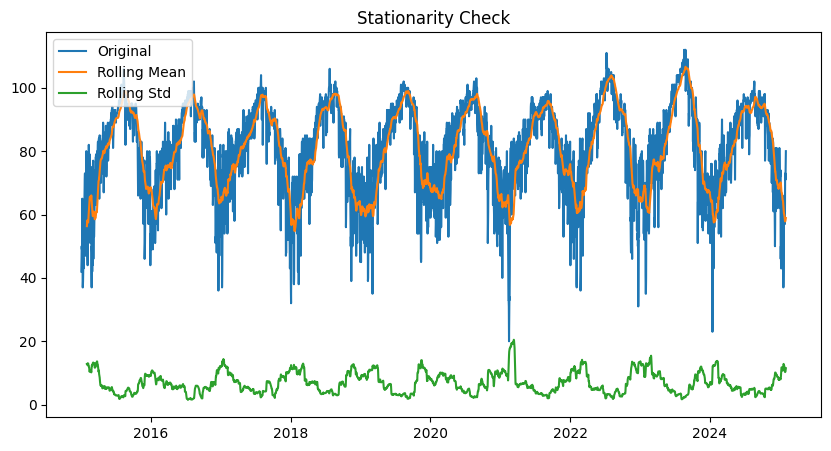

ADF Statistic: -4.1486793496277
p-value: 0.0008038441883827935


In [ ]:
from statsmodels.tsa.stattools import adfuller

rolling_mean = temperature_series.rolling(window=30).mean()
rolling_std = temperature_series.rolling(window=30).std()

plt.figure(figsize=(10, 5))
plt.plot(temperature_series, label='Original')
plt.plot(rolling_mean, label='Rolling Mean')
plt.plot(rolling_std, label='Rolling Std')
plt.legend()
plt.title('Stationarity Check')
plt.show()

result = adfuller(temperature_series.dropna())
print(f'ADF Statistic: {result[0]}')
print(f'p-value: {result[1]}')



**ACF and PACF Plot**

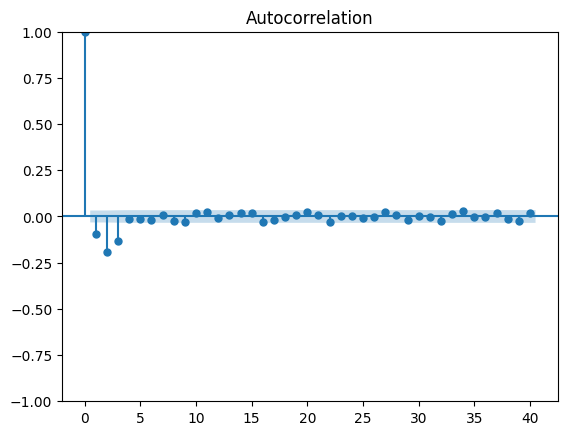

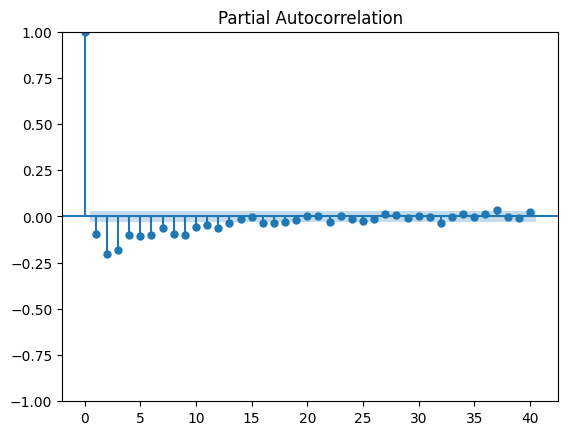

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

diff_series = temperature_series.diff().dropna()

plot_acf(diff_series, lags=40)
plot_pacf(diff_series, lags=40)
plt.show()


**Retrain ARIMA on Full Train+Val**

In [ ]:
full_train = pd.concat([train, val])
model_full = ARIMA(full_train, order=(1, 1, 1))
arima_model_full = model_full.fit()
test_predictions = arima_model_full.forecast(steps=len(test))

Test MSE: 648.027
Test MAE: 22.877
Test RMSE: 25.456
Test R-squared: -2.769





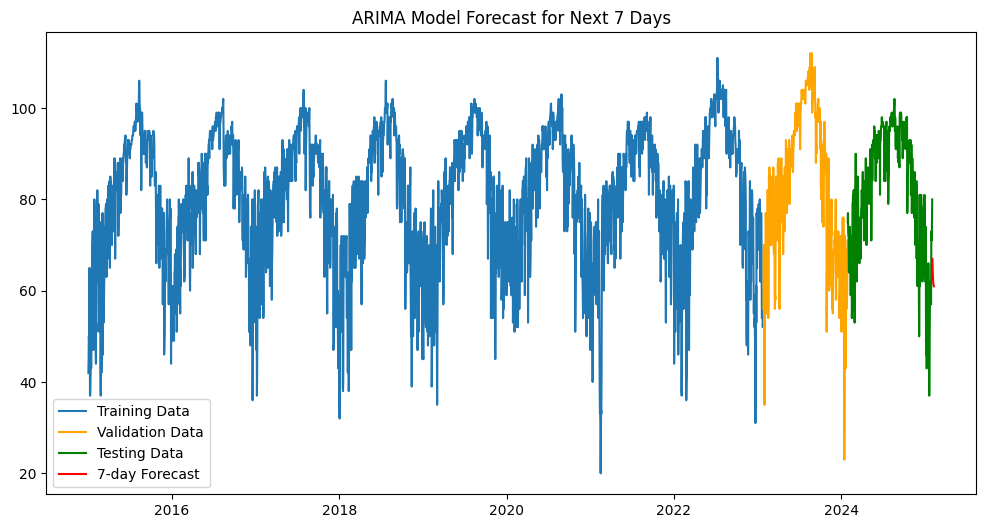

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import warnings
warnings.filterwarnings("ignore")

# Now, calculate the metrics
test_mse = mean_squared_error(test, test_predictions)
test_mae = mean_absolute_error(test, test_predictions)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(test, test_predictions)

test_predictions = arima_model_full.forecast(steps=len(test))
print(f'Test MSE: {mean_squared_error(test, test_predictions):.3f}')
print(f'Test MAE: {mean_absolute_error(test, test_predictions):.3f}')
print(f'Test RMSE: {np.sqrt(mean_squared_error(test, test_predictions)):.3f}')
print(f'Test R-squared: {r2_score(test, test_predictions):.3f}')
print("\n\n")


# Forecast for next 14 days
forecast = arima_model_full.forecast(steps=7)

plt.figure(figsize=(12, 6))
plt.plot(train.index, train, label='Training Data')
plt.plot(val.index, val, label='Validation Data', color='orange')
plt.plot(test.index, test, label='Testing Data', color='green')
plt.plot(pd.date_range(start=test.index[-1], periods=8, freq='D')[1:], forecast, label='7-day Forecast', color='red')
plt.title('ARIMA Model Forecast for Next 7 Days')
plt.legend()
plt.show()

**Forecast with Dates and Plot**

                 DATE  Predicted_TMAX
2024-01-30 2025-02-03       66.950083
2024-01-31 2025-02-04       64.483590
2024-02-01 2025-02-05       62.981438
2024-02-02 2025-02-06       62.066592
2024-02-03 2025-02-07       61.509430
2024-02-04 2025-02-08       61.170105
2024-02-05 2025-02-09       60.963448


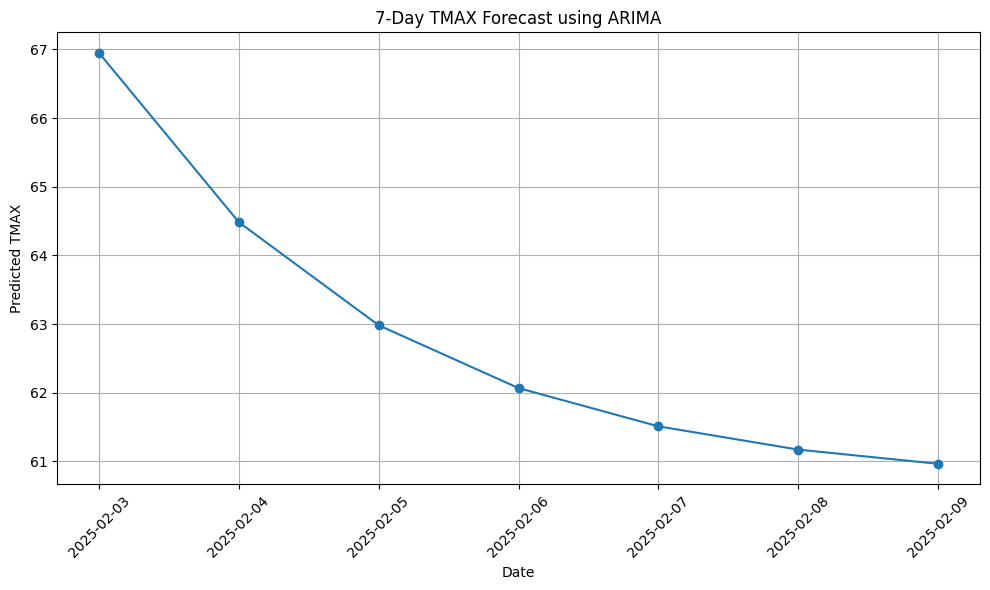

In [ ]:
last_date = brenham_df.index.max()
future_dates = pd.date_range(start=last_date + pd.DateOffset(days=1), periods=7)

forecast = arima_model_full.get_forecast(steps=7)
forecast_values = forecast.predicted_mean

forecast_df = pd.DataFrame({'DATE': future_dates, 'Predicted_TMAX': forecast_values})

print(forecast_df)

plt.figure(figsize=(10, 6))
plt.plot(forecast_df['DATE'], forecast_df['Predicted_TMAX'], marker='o', linestyle='-')
plt.xlabel('Date')
plt.ylabel('Predicted TMAX')
plt.title('7-Day TMAX Forecast using ARIMA')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()




**Loop through Different ARIMA Orders**

Order (1, 1, 0) -> Val MSE: 916.200, Val MAE: 26.307, Val RMSE: 30.269, Val R²: -2.153 | Test MSE: 320.048, Test MAE: 15.624, Test RMSE: 17.890, Test R²: -0.861
Order (1, 1, 1) -> Val MSE: 682.580, Val MAE: 22.270, Val RMSE: 26.126, Val R²: -1.349 | Test MSE: 648.027, Test MAE: 22.877, Test RMSE: 25.456, Test R²: -2.769
Order (2, 1, 2) -> Val MSE: 703.624, Val MAE: 22.654, Val RMSE: 26.526, Val R²: -1.421 | Test MSE: 655.021, Test MAE: 23.024, Test RMSE: 25.593, Test R²: -2.810
Order (0, 1, 1) -> Val MSE: 941.988, Val MAE: 26.737, Val RMSE: 30.692, Val R²: -2.241 | Test MSE: 343.549, Test MAE: 16.210, Test RMSE: 18.535, Test R²: -0.998
Order (2, 1, 0) -> Val MSE: 965.759, Val MAE: 27.139, Val RMSE: 31.077, Val R²: -2.323 | Test MSE: 374.067, Test MAE: 16.944, Test RMSE: 19.341, Test R²: -1.176
Order (1, 0, 1) -> Val MSE: 278.043, Val MAE: 13.975, Val RMSE: 16.675, Val R²: 0.043 | Test MSE: 172.172, Test MAE: 10.931, Test RMSE: 13.121, Test R²: -0.001
Order (1, 0, 0) -> Val MSE: 280.851

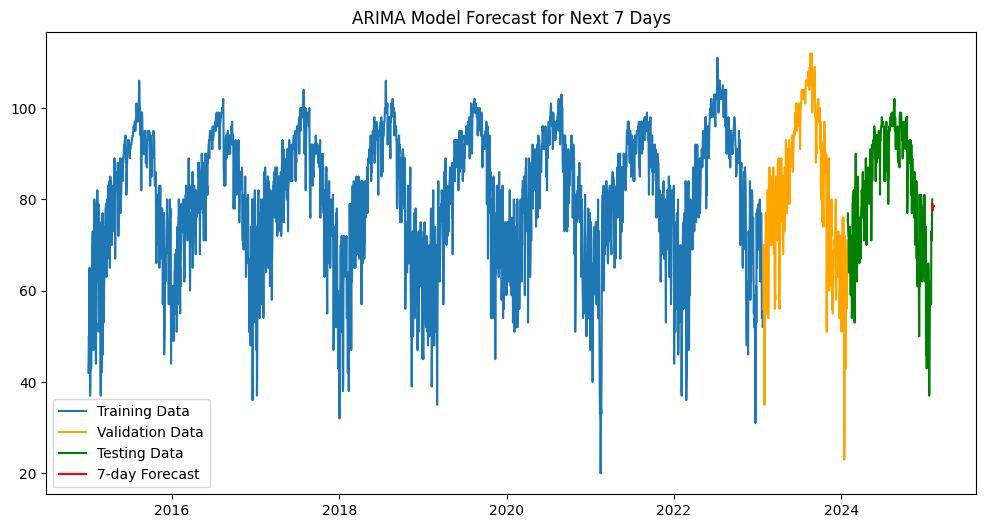

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# temperature_series = df['TMAX']
# train_size = int(len(temperature_series) * 0.9)
# val_size = len(temperature_series) - train_size
# train = temperature_series[:train_size]
# val = temperature_series[train_size:]
# test = test_df['TMAX']

arima_orders = [
    (1, 1, 0),
    (1, 1, 1),
    (2, 1, 2),
    (0, 1, 1),
    (2, 1, 0),
    (1, 0, 1),
    (1, 0, 0),
    (1, 1, 4),
    (1, 1, 6),
    (2, 1, 4),
    (2, 1, 6),
    (3, 1, 3),
    (4, 0, 0)
]

results = []

for order in arima_orders:
    try:
        model = ARIMA(train, order=order)
        arima_model = model.fit()

        val_predictions = arima_model.forecast(steps=len(val))
        val_mse = mean_squared_error(val, val_predictions)
        val_mae = mean_absolute_error(val, val_predictions)
        val_rmse = np.sqrt(val_mse)
        val_r2 = r2_score(val, val_predictions)

        full_train = pd.concat([train, val])
        model_full = ARIMA(full_train, order=order)
        arima_model_full = model_full.fit()

        # Ensure test and test_predictions have the same length and handle NaN values
        test.dropna(inplace=True)
        test_predictions = arima_model_full.forecast(steps=len(test))
        test_predictions = test_predictions[:len(test)]

        test_mse = mean_squared_error(test, test_predictions)
        test_mae = mean_absolute_error(test, test_predictions)
        test_rmse = np.sqrt(test_mse)
        test_r2 = r2_score(test, test_predictions)

        results.append((order, val_mse, val_mae, val_rmse, val_r2, test_mse, test_mae, test_rmse, test_r2))
        print(f'Order {order} -> '
              f'Val MSE: {val_mse:.3f}, Val MAE: {val_mae:.3f}, Val RMSE: {val_rmse:.3f}, Val R²: {val_r2:.3f} | '
              f'Test MSE: {test_mse:.3f}, Test MAE: {test_mae:.3f}, Test RMSE: {test_rmse:.3f}, Test R²: {test_r2:.3f}')
    except Exception as e:
        print(f'Failed for order {order}: {e}')

# Check if 'results' is empty before finding the minimum
if results:
    best_model = min(results, key=lambda x: x[5])
    best_order, _, _, _, _, best_test_mse, best_test_mae, best_test_rmse, best_test_r2 = best_model

    print(f'\nBest Model: Order {best_order} with Test MSE: {best_test_mse:.3f}, '
          f'Test MAE: {best_test_mae:.3f}, Test RMSE: {best_test_rmse:.3f}, Test R²: {best_test_r2:.3f}')

    final_model = ARIMA(pd.concat([train, val, test]), order=best_order)
    arima_final = final_model.fit()
    forecast = arima_final.forecast(steps=7)

    plt.figure(figsize=(12, 6))
    plt.plot(train.index, train, label='Training Data')
    plt.plot(val.index, val, label='Validation Data', color='orange')
    plt.plot(test.index, test, label='Testing Data', color='green')
    plt.plot(pd.date_range(start=test.index[-1], periods=8, freq='D')[1:], forecast, label='7-day Forecast', color='red')
    plt.title('ARIMA Model Forecast for Next 7 Days')
    plt.legend()
    plt.show()
else:
    print("No successful ARIMA models were fitted. Please check your data and model parameters.")

**Including AIC**

Order (1, 1, 0) -> Val MSE: 916.200, Val MAE: 26.307, Val RMSE: 30.269, Val R²: -2.153 | Test MSE: 320.048, Test MAE: 15.624, Test RMSE: 17.890, Test R²: -0.861 | Train AIC: 19604.72, Full Train AIC: 22083.21
Order (1, 1, 1) -> Val MSE: 682.580, Val MAE: 22.270, Val RMSE: 26.126, Val R²: -1.349 | Test MSE: 648.027, Test MAE: 22.877, Test RMSE: 25.456, Test R²: -2.769 | Train AIC: 19229.99, Full Train AIC: 21665.67
Order (2, 1, 2) -> Val MSE: 703.624, Val MAE: 22.654, Val RMSE: 26.526, Val R²: -1.421 | Test MSE: 655.021, Test MAE: 23.024, Test RMSE: 25.593, Test R²: -2.810 | Train AIC: 19188.20, Full Train AIC: 21617.29
Order (0, 1, 1) -> Val MSE: 941.988, Val MAE: 26.737, Val RMSE: 30.692, Val R²: -2.241 | Test MSE: 343.549, Test MAE: 16.210, Test RMSE: 18.535, Test R²: -0.998 | Train AIC: 19579.64, Full Train AIC: 22058.13
Order (2, 1, 0) -> Val MSE: 965.759, Val MAE: 27.139, Val RMSE: 31.077, Val R²: -2.323 | Test MSE: 374.067, Test MAE: 16.944, Test RMSE: 19.341, Test R²: -1.176 | T

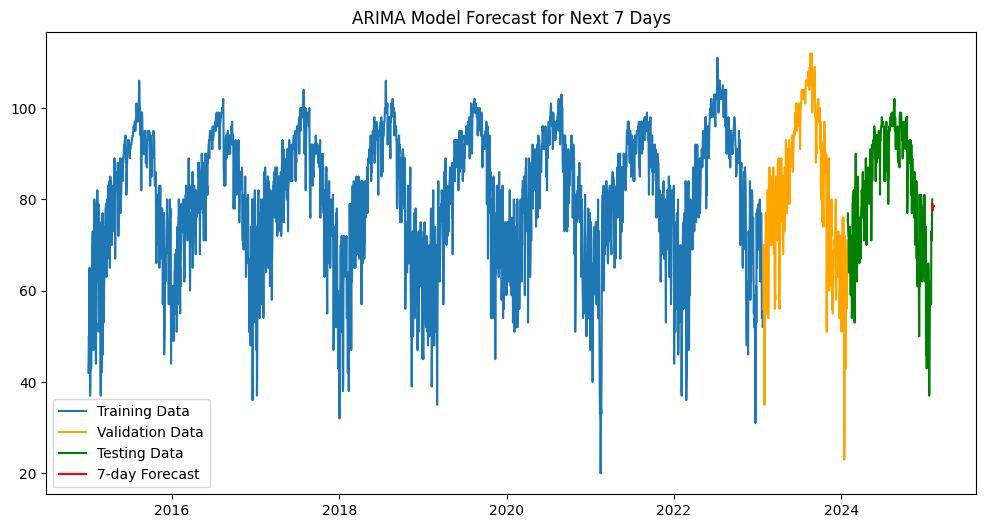

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# # We are only interested in predicting TMAX
# temperature_series = df['TMAX']

# # Define train, validation, and test sizes
# train_size = int(len(temperature_series) * 0.8)
# val_size = int(len(temperature_series) * 0.1)
# test_size = len(temperature_series) - train_size - val_size

# # Split the data
# train = temperature_series[:train_size]
# val = temperature_series[train_size:train_size + val_size]
# test = temperature_series[train_size + val_size:]

# Different ARIMA configurations to test
arima_orders = [
    (1, 1, 0),
    (1, 1, 1),
    (2, 1, 2),
    (0, 1, 1),
    (2, 1, 0),
    (1, 0, 1),
    (1, 0, 0),
    (1, 1, 4),
    (1, 1, 6),
    (2, 1, 4),
    (2, 1, 6),
    (3, 1, 3),
    (4, 0, 0)
]

results = []

for order in arima_orders:
    try:
        # Fit ARIMA Model on Training Data
        model = ARIMA(train, order=order)
        arima_model = model.fit()
        train_aic = arima_model.aic

        # Evaluate on Validation Set
        val_predictions = arima_model.forecast(steps=len(val))
        val_mse = mean_squared_error(val, val_predictions)
        val_mae = mean_absolute_error(val, val_predictions)
        val_rmse = np.sqrt(val_mse)
        val_r2 = r2_score(val, val_predictions)

        # Retrain the model on training + validation data
        full_train = pd.concat([train, val])
        model_full = ARIMA(full_train, order=order)
        arima_model_full = model_full.fit()
        full_train_aic = arima_model_full.aic

        # Evaluate on Test Set
        test_predictions = arima_model_full.forecast(steps=len(test))
        test_mse = mean_squared_error(test, test_predictions)
        test_mae = mean_absolute_error(test, test_predictions)
        test_rmse = np.sqrt(test_mse)
        test_r2 = r2_score(test, test_predictions)

        results.append((order, val_mse, val_mae, val_rmse, val_r2,
                        test_mse, test_mae, test_rmse, test_r2,
                        train_aic, full_train_aic))

        print(f'Order {order} -> '
              f'Val MSE: {val_mse:.3f}, Val MAE: {val_mae:.3f}, Val RMSE: {val_rmse:.3f}, Val R²: {val_r2:.3f} | '
              f'Test MSE: {test_mse:.3f}, Test MAE: {test_mae:.3f}, Test RMSE: {test_rmse:.3f}, Test R²: {test_r2:.3f} | '
              f'Train AIC: {train_aic:.2f}, Full Train AIC: {full_train_aic:.2f}')

    except Exception as e:
        print(f'Failed for order {order}: {e}')

# Select the best model based on the lowest test MSE
best_model = min(results, key=lambda x: x[5])  # Sort by test MSE
(best_order, _, _, _, _, best_test_mse, best_test_mae,
 best_test_rmse, best_test_r2, best_train_aic, best_full_aic) = best_model

# Print best model's evaluation metrics
print(f'\nBest Model: Order {best_order} with Test MSE: {best_test_mse:.3f}, '
      f'Test MAE: {best_test_mae:.3f}, Test RMSE: {best_test_rmse:.3f}, Test R²: {best_test_r2:.3f}, '
      f'Train AIC: {best_train_aic:.2f}, Full Train AIC: {best_full_aic:.2f}')

# Fit and Forecast with Best Model
final_model = ARIMA(pd.concat([train, val, test]), order=best_order)
arima_final = final_model.fit()
forecast = arima_final.forecast(steps=7)

# Plotting the results
plt.figure(figsize=(12, 6))
plt.plot(train.index, train, label='Training Data')
plt.plot(val.index, val, label='Validation Data', color='orange')
plt.plot(test.index, test, label='Testing Data', color='green')
plt.plot(pd.date_range(start=test.index[-1], periods=8, freq='D')[1:], forecast, label='7-day Forecast', color='red')
plt.title('ARIMA Model Forecast for Next 7 Days')
plt.legend()
plt.show()


**7 day forecast**

                 DATE  Predicted_TMAX
2025-02-03 2025-02-03       78.966545
2025-02-04 2025-02-04       77.663871
2025-02-05 2025-02-05       77.598880
2025-02-06 2025-02-06       78.236349
2025-02-07 2025-02-07       78.557228
2025-02-08 2025-02-08       78.564062
2025-02-09 2025-02-09       78.556392


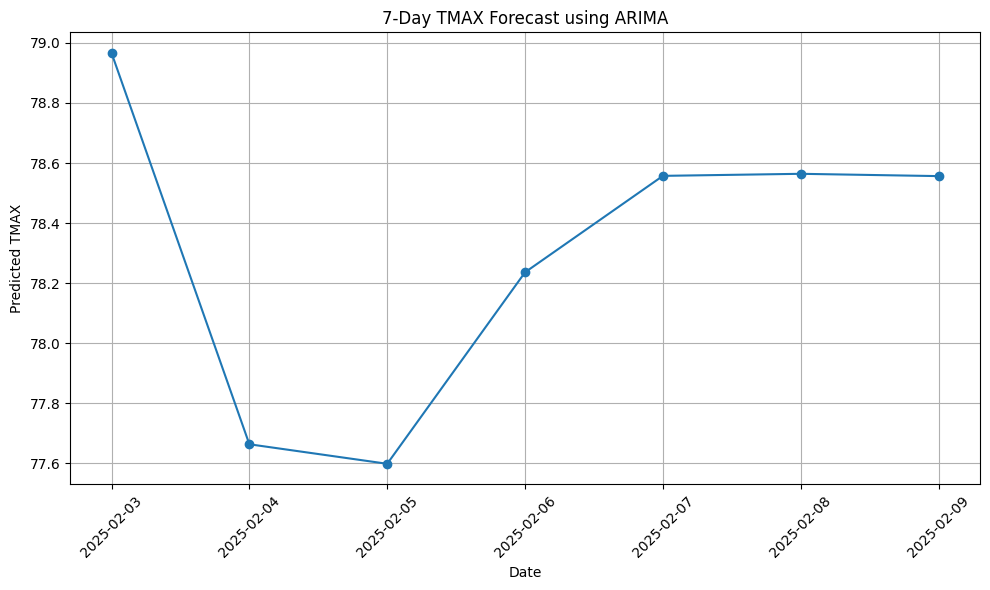

In [ ]:
import warnings
warnings.filterwarnings("ignore")

last_date = brenham_df.index.max()
future_dates = pd.date_range(start=last_date + pd.DateOffset(days=1), periods=7)

forecast = arima_final.get_forecast(steps=7)
forecast_values = forecast.predicted_mean

forecast_df = pd.DataFrame({'DATE': future_dates, 'Predicted_TMAX': forecast_values})

print(forecast_df)

plt.figure(figsize=(10, 6))
plt.plot(forecast_df['DATE'], forecast_df['Predicted_TMAX'], marker='o', linestyle='-')
plt.xlabel('Date')
plt.ylabel('Predicted TMAX')
plt.title('7-Day TMAX Forecast using ARIMA')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()



##**SARIMA**

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

**Fit on training data**

In [ ]:
# Fit SARIMA Model on Training Data
model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 26))
sarima_model = model.fit(disp=False)

# Evaluate on Validation Set
val_predictions = sarima_model.forecast(steps=len(val))
val_mse = mean_squared_error(val, val_predictions)
val_mae = mean_absolute_error(val, val_predictions)
val_rmse = np.sqrt(val_mse)
val_r2 = r2_score(val, val_predictions)
print(f'Validation MSE: {val_mse:.3f}')
print(f'Validation MAE: {val_mae:.3f}')
print(f'Validation RMSE: {val_rmse:.3f}')
print(f'Validation R²: {val_r2:.3f}')

Validation MSE: 649.021
Validation MAE: 21.676
Validation RMSE: 25.476
Validation R²: -1.233


**Retrain on train+val**

In [ ]:
# Retrain the model on training + validation data for final testing and forecasting
full_train = pd.concat([train, val])
model_full = SARIMAX(full_train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 26))
sarima_model_full = model_full.fit(disp=False)

# Evaluate on Test Set
test_predictions = sarima_model_full.forecast(steps=len(test))
test_mse = mean_squared_error(test, test_predictions)
test_mae = mean_absolute_error(test, test_predictions)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(test, test_predictions)
print(f'Test MSE: {test_mse:.3f}')
print(f'Test MAE: {test_mae:.3f}')
print(f'Test RMSE: {test_rmse:.3f}')
print(f'Test R²: {test_r2:.3f}')

Test MSE: 617.118
Test MAE: 22.262
Test RMSE: 24.842
Test R²: -2.589


**Plot for next 7 days**

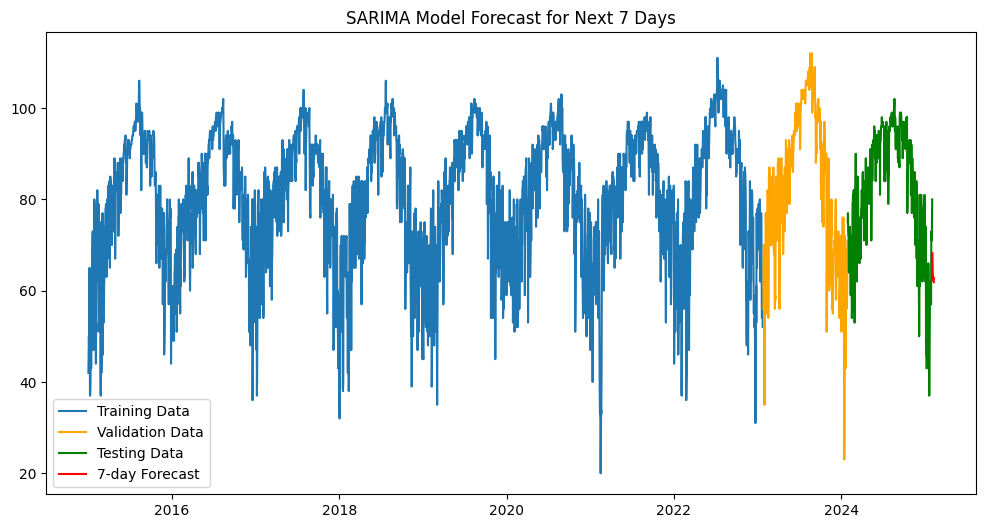

In [ ]:
# Forecast the next 7 days
forecast = sarima_model_full.forecast(steps=7)

# Plotting the results
plt.figure(figsize=(12, 6))
plt.plot(train.index, train, label='Training Data')
plt.plot(val.index, val, label='Validation Data', color='orange')
plt.plot(test.index, test, label='Testing Data', color='green')
plt.plot(pd.date_range(start=test.index[-1], periods=8, freq='D')[1:], forecast, label='7-day Forecast', color='red')
plt.title('SARIMA Model Forecast for Next 7 Days')
plt.legend()
plt.show()

Order (0, 1, 1), Seasonal Order (0, 1, 1, 26) -> Val MSE: 905.508, Val MAE: 26.111, Val RMSE: 30.092, Val R²: -2.116 | Test MSE: 307.880, Test MAE: 15.371, Test RMSE: 17.547, Test R²: -0.791
Order (1, 1, 1), Seasonal Order (1, 1, 1, 26) -> Val MSE: 649.021, Val MAE: 21.676, Val RMSE: 25.476, Val R²: -1.233 | Test MSE: 617.118, Test MAE: 22.262, Test RMSE: 24.842, Test R²: -2.589
Order (2, 1, 2), Seasonal Order (1, 1, 1, 26) -> Val MSE: 667.892, Val MAE: 22.022, Val RMSE: 25.844, Val R²: -1.298 | Test MSE: 621.104, Test MAE: 22.352, Test RMSE: 24.922, Test R²: -2.612
Order (1, 1, 1), Seasonal Order (0, 0, 0, 26) -> Val MSE: 682.580, Val MAE: 22.270, Val RMSE: 26.126, Val R²: -1.349 | Test MSE: 648.027, Test MAE: 22.877, Test RMSE: 25.456, Test R²: -2.769
Order (4, 0, 0), Seasonal Order (0, 1, 0, 26) -> Val MSE: 634.779, Val MAE: 21.128, Val RMSE: 25.195, Val R²: -1.184 | Test MSE: 877.026, Test MAE: 24.975, Test RMSE: 29.615, Test R²: -4.101

Best Model: Order (0, 1, 1), Seasonal Order 

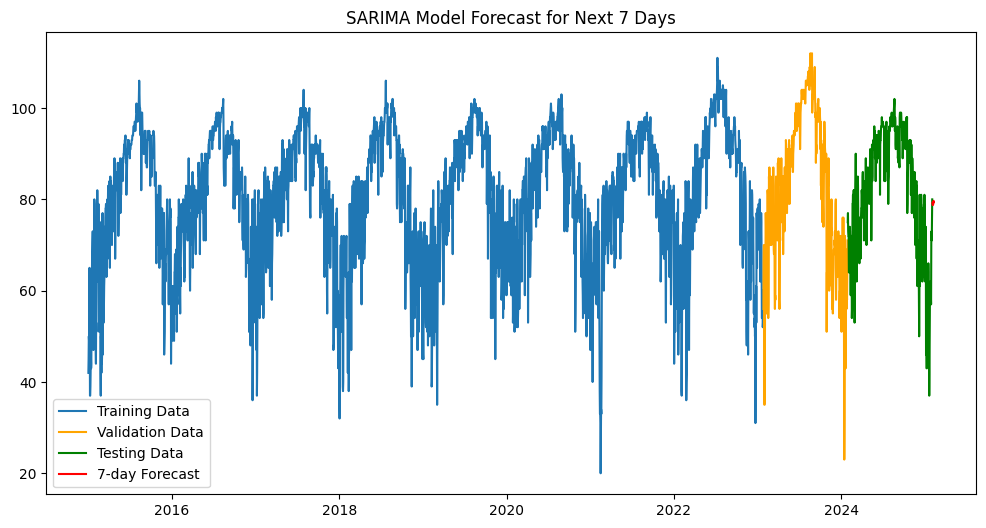

In [ ]:
# Different SARIMA configurations to test
sarima_orders = [
    ((0,1,1), (0,1,1,26)),
    ((1,1,1), (1,1,1,26)),
    ((2,1,2), (1,1,1,26)),
    ((1,1,1), (0,0,0,26)),
    ((4,0,0), (0,1,0,26))
]

results = []

for order, seasonal_order in sarima_orders:
    try:
        # Fit SARIMA Model on Training Data
        model = SARIMAX(train, order=order, seasonal_order=seasonal_order)
        sarima_model = model.fit(disp=False)

        # Evaluate on Validation Set
        val_predictions = sarima_model.forecast(steps=len(val))
        val_mse = mean_squared_error(val, val_predictions)
        val_mae = mean_absolute_error(val, val_predictions)
        val_rmse = np.sqrt(val_mse)
        val_r2 = r2_score(val, val_predictions)

        # Retrain the model on training + validation data
        full_train = pd.concat([train, val])
        model_full = SARIMAX(full_train, order=order, seasonal_order=seasonal_order)
        sarima_model_full = model_full.fit(disp=False)

        # Evaluate on Test Set
        test_predictions = sarima_model_full.forecast(steps=len(test))
        test_mse = mean_squared_error(test, test_predictions)
        test_mae = mean_absolute_error(test, test_predictions)
        test_rmse = np.sqrt(test_mse)
        test_r2 = r2_score(test, test_predictions)

        results.append((order, seasonal_order, val_mse, val_mae, val_rmse, val_r2, test_mse, test_mae, test_rmse, test_r2))
        print(f'Order {order}, Seasonal Order {seasonal_order} -> '
              f'Val MSE: {val_mse:.3f}, Val MAE: {val_mae:.3f}, Val RMSE: {val_rmse:.3f}, Val R²: {val_r2:.3f} | '
              f'Test MSE: {test_mse:.3f}, Test MAE: {test_mae:.3f}, Test RMSE: {test_rmse:.3f}, Test R²: {test_r2:.3f}')
    except Exception as e:
        print(f'Failed for order {order}, seasonal_order {seasonal_order}: {e}')

# Select the best model based on the lowest test MSE
best_model = min(results, key=lambda x: x[6])  # Sort by test MSE
best_order, best_seasonal_order, _, _, _, _, best_test_mse, best_test_mae, best_test_rmse, best_test_r2 = best_model

# Print best model's evaluation metrics
print(f'\nBest Model: Order {best_order}, Seasonal Order {best_seasonal_order} with Test MSE: {best_test_mse:.3f}, '
      f'Test MAE: {best_test_mae:.3f}, Test RMSE: {best_test_rmse:.3f}, Test R²: {best_test_r2:.3f}')

# Fit and Forecast with Best Model
final_model = SARIMAX(pd.concat([train, val, test]), order=best_order, seasonal_order=best_seasonal_order)
sarima_final = final_model.fit(disp=False)
forecast = sarima_final.forecast(steps=7)

# Plotting the results
plt.figure(figsize=(12, 6))
plt.plot(train.index, train, label='Training Data')
plt.plot(val.index, val, label='Validation Data', color='orange')
plt.plot(test.index, test, label='Testing Data', color='green')
plt.plot(pd.date_range(start=test.index[-1], periods=8, freq='D')[1:], forecast, label='7-day Forecast', color='red')
plt.title('SARIMA Model Forecast for Next 7 Days')
plt.legend()
plt.show()

**7 day forecast**

                 DATE  Predicted_TMAX
2025-02-03 2025-02-03       79.207263
2025-02-04 2025-02-04       78.752455
2025-02-05 2025-02-05       78.770741
2025-02-06 2025-02-06       78.849981
2025-02-07 2025-02-07       79.488557
2025-02-08 2025-02-08       79.684666
2025-02-09 2025-02-09       79.366770


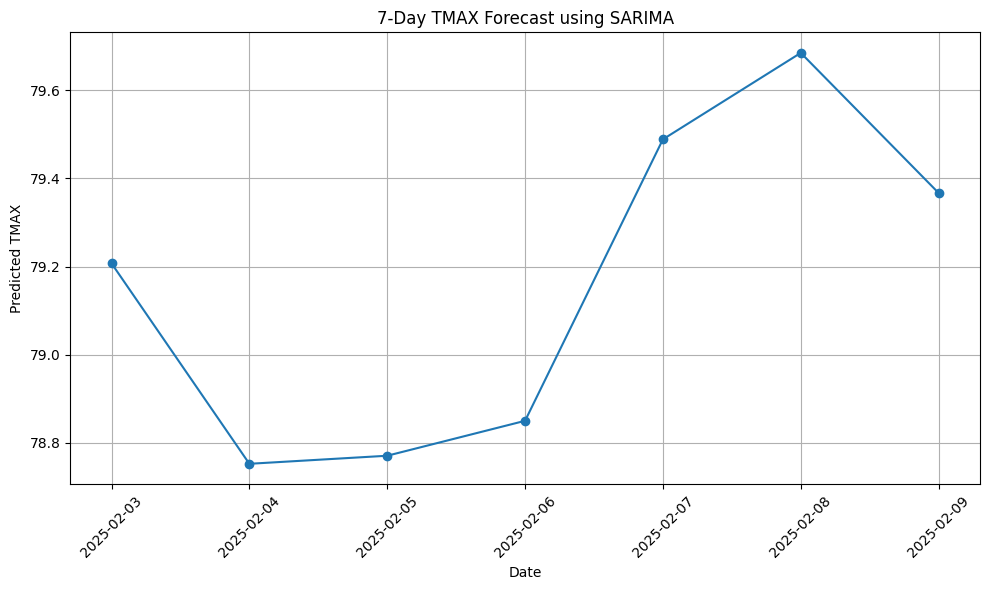

In [ ]:
import warnings
warnings.filterwarnings("ignore")


# Assuming 'DATE' was renamed to 'index' during model training
# Use brenham_df.index if 'DATE' was used as the index
# or use the actual column name where the date is stored

# If 'DATE' is used as the index:
last_date = brenham_df.index.max()

# If 'DATE' was renamed:
# last_date = brenham_df['YourDateColumnName'].max()

# Create future dates for the next 7 days
future_dates = pd.date_range(start=last_date + pd.DateOffset(days=1), periods=7)

# Forecast the next 7 days using the SARIMA model
forecast = sarima_final.get_forecast(steps=7)

# Extract the predicted mean values
forecast_values = forecast.predicted_mean

# Create a DataFrame for the forecast
forecast_df = pd.DataFrame({'DATE': future_dates, 'Predicted_TMAX': forecast_values})

# Display the forecast
print(forecast_df)


# Plotting
plt.figure(figsize=(10, 6))
plt.plot(forecast_df['DATE'], forecast_df['Predicted_TMAX'], marker='o', linestyle='-')
plt.xlabel('Date')
plt.ylabel('Predicted TMAX')
plt.title('7-Day TMAX Forecast using SARIMA')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## **Linear Regression**

In [ ]:
# Add temporal features
for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5 #Creating the isWeekend column within the loop

# Add lag and trend features to train
for lag in range(1, 8):
    train_df[f'TMAX_lag_{lag}'] = train_df['TMAX'].shift(lag)
    train_df[f'TMIN_lag_{lag}'] = train_df['TMIN'].shift(lag)
    train_df[f'PRCP_lag_{lag}'] = train_df['PRCP'].shift(lag)
train_df['TMAX_3day_avg'] = train_df['TMAX'].rolling(3).mean() #Creating TMAX_3day_avg
train_df['PRCP_3day_sum'] = train_df['PRCP'].rolling(3).sum() #Creating PRCP_3day_sum
train_df['TMAX_trend'] = train_df['TMAX'] - train_df['TMAX'].shift(1) #Creating TMAX_trend

train_df = train_df.dropna().copy()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Ensure DATE is datetime
train_df['DATE'] = pd.to_datetime(train_df['DATE'], errors='coerce')
test_df['DATE'] = pd.to_datetime(test_df['DATE'], errors='coerce')

# Add temporal features
for df in [train_df, test_df]:
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

# Add lag and trend features to train
for lag in range(1, 8):
    train_df[f'TMAX_lag_{lag}'] = train_df['TMAX'].shift(lag)
    train_df[f'TMIN_lag_{lag}'] = train_df['TMIN'].shift(lag)
    train_df[f'PRCP_lag_{lag}'] = train_df['PRCP'].shift(lag)
train_df['TMAX_3day_avg'] = train_df['TMAX'].rolling(3).mean()
train_df['PRCP_3day_sum'] = train_df['PRCP'].rolling(3).sum()
train_df['TMAX_trend'] = train_df['TMAX'] - train_df['TMAX'].shift(1)
train_df.dropna(inplace=True)

# Add same to test
for lag in range(1, 8):
    test_df[f'TMAX_lag_{lag}'] = test_df['TMAX'].shift(lag)
    test_df[f'TMIN_lag_{lag}'] = test_df['TMIN'].shift(lag)
    test_df[f'PRCP_lag_{lag}'] = test_df['PRCP'].shift(lag)
test_df['TMAX_3day_avg'] = test_df['TMAX'].rolling(3).mean()
test_df['PRCP_3day_sum'] = test_df['PRCP'].rolling(3).sum()
test_df['TMAX_trend'] = test_df['TMAX'] - test_df['TMAX'].shift(1)
test_df.dropna(inplace=True)

# Feature selection
feature_cols = ['TMIN', 'PRCP', 'SOLAR RADIATION', 'Month', 'DayOfYear', 'WeekOfYear',
                'DayOfWeek', 'IsWeekend', 'TMAX_3day_avg', 'PRCP_3day_sum', 'TMAX_trend'] + \
               [f'TMAX_lag_{i}' for i in range(1, 8)] + \
               [f'TMIN_lag_{i}' for i in range(1, 8)] + \
               [f'PRCP_lag_{i}' for i in range(1, 8)]

# Split
X = train_df[feature_cols]
y = train_df['TMAX']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, shuffle=False)

# --- ADD MISSING LINEAR REGRESSION SETUP ---
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

param_dist = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'copy_X': [True, False]
}

search = RandomizedSearchCV(
    lr_model,
    param_distributions=param_dist,
    n_iter=10,
    scoring='neg_mean_squared_error',
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

# Train
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("✅ Best Parameters:", search.best_params_)



Fitting 3 folds for each of 8 candidates, totalling 24 fits
✅ Best Parameters: {'positive': True, 'fit_intercept': True, 'copy_X': True}


In [ ]:

X_test = test_df[feature_cols]
y_test = test_df['TMAX']
test_df['Predicted_TMAX'] = best_model.predict(X_test)
test_df['Predicted_TMAX'] = best_model.predict(X_test)

In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure dates are sorted
test_df = test_df.sort_values('DATE')
last_7_days = test_df.tail(7).copy()

# Reset index to bring 'DATE' back as a column if it's the index
last_7_days = last_7_days.reset_index()

last_date = last_7_days['DATE'].max()

# 1. Create future dates
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=7)
forecast_df = pd.DataFrame({'DATE': future_dates})

# 2. Time-based features
forecast_df['Month'] = forecast_df['DATE'].dt.month
forecast_df['DayOfYear'] = forecast_df['DATE'].dt.dayofyear
forecast_df['WeekOfYear'] = forecast_df['DATE'].dt.isocalendar().week.astype(int)
forecast_df['DayOfWeek'] = forecast_df['DATE'].dt.weekday
forecast_df['IsWeekend'] = forecast_df['DayOfWeek'] >= 5

# 3. Rolling and trend features
forecast_df['TMAX_3day_avg'] = last_7_days['TMAX'].tail(3).mean()
forecast_df['PRCP_3day_sum'] = last_7_days['PRCP'].tail(3).sum()
forecast_df['TMAX_trend'] = last_7_days['TMAX'].iloc[-1] - last_7_days['TMAX'].iloc[-2]

# 4. Static feature averages from training data
forecast_df['TMIN'] = train_df['TMIN'].mean()
forecast_df['PRCP'] = train_df['PRCP'].mean()
forecast_df['SOLAR RADIATION'] = train_df['SOLAR RADIATION'].mean()

# 5. Initialize lag columns
for lag in range(1, 8):
    forecast_df[f'TMAX_lag_{lag}'] = last_7_days['TMAX'].values[-lag]
    forecast_df[f'TMIN_lag_{lag}'] = last_7_days['TMIN'].values[-lag]
    forecast_df[f'PRCP_lag_{lag}'] = last_7_days['PRCP'].values[-lag]

# 6. Prediction loop
predictions = []

for i in range(7):
    # Update lag features from previous predictions
    for lag in range(1, 8):
        if i >= lag:
            forecast_df.loc[i, f'TMAX_lag_{lag}'] = predictions[i - lag]

    x_input = forecast_df.iloc[[i]][feature_cols].copy()

    # Fill NaNs using training data mean
    for col in feature_cols:
        if x_input[col].isnull().any():
            x_input[col] = x_input[col].fillna(train_df[col].mean())

    # Predict
    pred = best_model.predict(x_input)[0]
    predictions.append(pred)

X_test = test_df[feature_cols]
y_test = test_df['TMAX']
test_df['Predicted_TMAX'] = best_model.predict(X_test)
test_df['Predicted_TMAX'] = best_model.predict(X_test)


In [ ]:
# Save to CSV
output_df = test_df[['DATE', 'TMAX', 'Predicted_TMAX']]
output_df.to_csv("Full_Test_Set_Forecast_ManualUpdation.csv", index=False)

In [ ]:
# ✅ Train Set Predictions & Metrics
# Use the best model from the search, not the original lr_model
train_preds = best_model.predict(X_train)  # Changed from lr_model to best_model
train_r2 = r2_score(y_train, train_preds)
train_mae = mean_absolute_error(y_train, train_preds)
train_mse = mean_squared_error(y_train, train_preds)
train_rmse = np.sqrt(train_mse)

# 📊 Print Performance
print("\n✅ Train Set Performance:")
print(f"R² Score: {train_r2:.4f}, MAE: {train_mae:.4f}, MSE: {train_mse:.4f}, RMSE: {train_rmse:.4f}")


✅ Train Set Performance:
R² Score: 1.0000, MAE: 0.0000, MSE: 0.0000, RMSE: 0.0000


In [ ]:
# Test set Evaluate
# Ensure y_test and output_df are aligned before calculating metrics
# Use the DATE column as a common index
output_df = output_df.set_index('DATE')
test_df = test_df.set_index('DATE')
y_test_aligned = test_df.loc[output_df.index, 'TMAX']  # Select y_test values corresponding to the output_df index

# Now calculate metrics using the aligned y_test
r2 = r2_score(y_test_aligned, output_df['Predicted_TMAX'])
mae = mean_absolute_error(y_test_aligned, output_df['Predicted_TMAX'])
mse = mean_squared_error(y_test_aligned, output_df['Predicted_TMAX'])
rmse = np.sqrt(mse)

print("\n📊 Test Set Performance (Full Test Forecast):")
print(f"R² Score: {r2:.4f}, MAE: {mae:.4f}, MSE: {mse:.4f}, RMSE: {rmse:.4f}")


📊 Test Set Performance (Full Test Forecast):
R² Score: 1.0000, MAE: 0.0000, MSE: 0.0000, RMSE: 0.0000


**TMAX Prediction for next 7 days**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ensure dates are sorted
test_df = test_df.sort_values('DATE')
last_7_days = test_df.tail(7).copy()

# Reset index to bring 'DATE' back as a column if it's the index
last_7_days = last_7_days.reset_index()

last_date = last_7_days['DATE'].max()

# 1. Create future dates
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=7)
forecast_df = pd.DataFrame({'DATE': future_dates})

# 2. Time-based features
forecast_df['Month'] = forecast_df['DATE'].dt.month
forecast_df['DayOfYear'] = forecast_df['DATE'].dt.dayofyear
forecast_df['WeekOfYear'] = forecast_df['DATE'].dt.isocalendar().week.astype(int)
forecast_df['DayOfWeek'] = forecast_df['DATE'].dt.weekday
forecast_df['IsWeekend'] = forecast_df['DayOfWeek'] >= 5

# 3. Rolling and trend features
forecast_df['TMAX_3day_avg'] = last_7_days['TMAX'].tail(3).mean()
forecast_df['PRCP_3day_sum'] = last_7_days['PRCP'].tail(3).sum()
forecast_df['TMAX_trend'] = last_7_days['TMAX'].iloc[-1] - last_7_days['TMAX'].iloc[-2]

# 4. Static feature averages from training data
forecast_df['TMIN'] = train_df['TMIN'].mean()
forecast_df['PRCP'] = train_df['PRCP'].mean()
forecast_df['SOLAR RADIATION'] = train_df['SOLAR RADIATION'].mean()

# 5. Initialize lag columns
for lag in range(1, 8):
    forecast_df[f'TMAX_lag_{lag}'] = last_7_days['TMAX'].values[-lag]
    forecast_df[f'TMIN_lag_{lag}'] = last_7_days['TMIN'].values[-lag]
    forecast_df[f'PRCP_lag_{lag}'] = last_7_days['PRCP'].values[-lag]

# 6. Prediction loop
predictions = []

for i in range(7):
    # Update lag features from previous predictions
    for lag in range(1, 8):
        if i >= lag:
            forecast_df.loc[i, f'TMAX_lag_{lag}'] = predictions[i - lag]

    x_input = forecast_df.iloc[[i]][feature_cols].copy()

    # Fill NaNs using training data mean
    for col in feature_cols:
        if x_input[col].isnull().any():
            x_input[col] = x_input[col].fillna(train_df[col].mean())

    # Predict
    pred = best_model.predict(x_input)[0]
    predictions.append(pred)

        DATE  Predicted_TMAX
0 2025-02-03            84.0
1 2025-02-04            88.0
2 2025-02-05            92.0
3 2025-02-06            96.0
4 2025-02-07           100.0
5 2025-02-08           104.0
6 2025-02-09           108.0


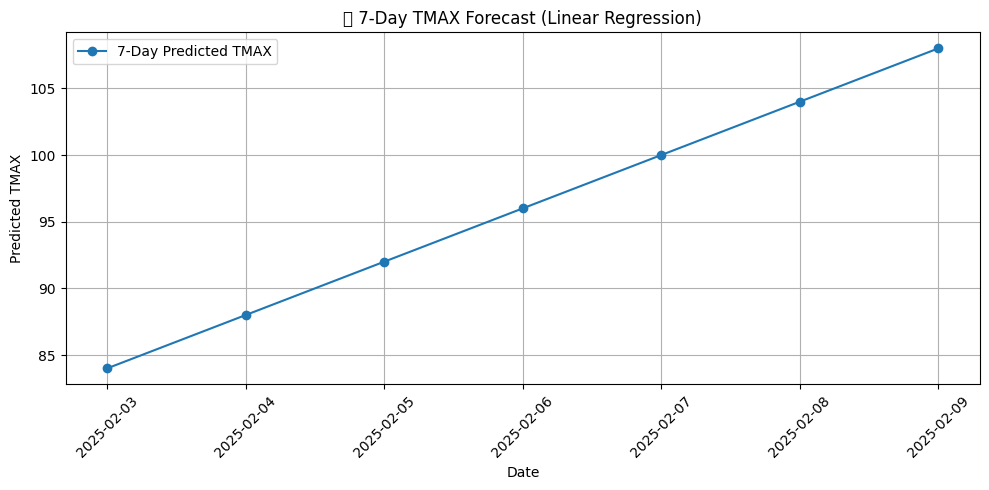

✅ Forecast saved to 'LinearRegression_7Day_Forecast.xlsx'


In [ ]:
# 7. Save predictions
forecast_df['Predicted_TMAX'] = predictions
print(forecast_df[['DATE', 'Predicted_TMAX']])

# 8. Plot the results
plt.figure(figsize=(10, 5))
plt.plot(forecast_df['DATE'], forecast_df['Predicted_TMAX'], marker='o', label='7-Day Predicted TMAX')
plt.xlabel("Date")
plt.ylabel("Predicted TMAX")
plt.title("📈 7-Day TMAX Forecast (Linear Regression)")
plt.grid(True)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# 9. Save to Excel
forecast_df.to_excel("LinearRegression_7Day_Forecast.xlsx", index=False)
print("✅ Forecast saved to 'LinearRegression_7Day_Forecast.xlsx'")


## **SVM**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings("ignore")

# --- Step 1: Date features ---
for df in [train_df, test_df]:
    # Check if 'DATE' is already a column, if not, reset index
    if 'DATE' not in df.columns:
        df = df.reset_index()

    df['DATE'] = pd.to_datetime(df['DATE'], errors='coerce')
    df['Month'] = df['DATE'].dt.month
    df['DayOfYear'] = df['DATE'].dt.dayofyear
    df['WeekOfYear'] = df['DATE'].dt.isocalendar().week.astype(int)
    df['DayOfWeek'] = df['DATE'].dt.weekday
    df['IsWeekend'] = df['DayOfWeek'] >= 5

# --- Step 2: Lag and rolling features ---
for lag in range(1, 8):
    train_df[f'TMAX_lag_{lag}'] = train_df['TMAX'].shift(lag)
    train_df[f'TMIN_lag_{lag}'] = train_df['TMIN'].shift(lag)
    train_df[f'PRCP_lag_{lag}'] = train_df['PRCP'].shift(lag)

train_df['TMAX_3day_avg'] = train_df['TMAX'].rolling(3).mean()
train_df['PRCP_3day_sum'] = train_df['PRCP'].rolling(3).sum()
train_df['TMAX_trend'] = train_df['TMAX'] - train_df['TMAX'].shift(1)
train_df.dropna(inplace=True)

for lag in range(1, 8):
    test_df[f'TMAX_lag_{lag}'] = test_df['TMAX'].shift(lag)
    test_df[f'TMIN_lag_{lag}'] = test_df['TMIN'].shift(lag)
    test_df[f'PRCP_lag_{lag}'] = test_df['PRCP'].shift(lag)

test_df['TMAX_3day_avg'] = test_df['TMAX'].rolling(3).mean()
test_df['PRCP_3day_sum'] = test_df['PRCP'].rolling(3).sum()
test_df['TMAX_trend'] = test_df['TMAX'] - test_df['TMAX'].shift(1)
test_df.dropna(inplace=True)

# --- Step 3: Feature columns ---
feature_cols = ['TMIN', 'PRCP', 'SOLAR RADIATION', 'Month', 'DayOfYear', 'WeekOfYear',
                'DayOfWeek', 'IsWeekend', 'TMAX_3day_avg', 'PRCP_3day_sum', 'TMAX_trend'] + \
               [f'TMAX_lag_{i}' for i in range(1, 8)] + \
               [f'TMIN_lag_{i}' for i in range(1, 8)] + \
               [f'PRCP_lag_{i}' for i in range(1, 8)]

# --- Step 4: Train-validation split ---
X = train_df[feature_cols]
y = train_df['TMAX']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, shuffle=False)

# --- Step 5: SVM Model + RandomizedSearchCV (fast version) ---
param_dist = {
    'C': [1, 10],                   # Reduced grid
    'gamma': ['scale', 0.1],        # Common gamma values
    'kernel': ['rbf']               # Use only RBF for now
}

svr = SVR()
search = RandomizedSearchCV(
    svr,
    param_distributions=param_dist,
    n_iter=4,                       # Speed optimized
    scoring='neg_mean_squared_error',
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

search.fit(X_train, y_train)
best_model = search.best_estimator_
print("✅ Best Parameters:", search.best_params_)

# --- Step 6: Predict on test set ---
X_test = test_df[feature_cols]
y_test = test_df['TMAX']
test_df['Predicted_TMAX'] = best_model.predict(X_test)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
✅ Best Parameters: {'kernel': 'rbf', 'gamma': 'scale', 'C': 10}


In [ ]:
# Save to CSV
output_df = test_df.reset_index()[['DATE', 'TMAX', 'Predicted_TMAX']] # Reset index before selecting columns
output_df.to_csv("Full_Test_Set_Forecast_SVM.csv", index=False)

In [ ]:
# ✅ Train Set Predictions & Metrics
train_preds = best_model.predict(X_train)
train_r2 = r2_score(y_train, train_preds)
train_mae = mean_absolute_error(y_train, train_preds)
train_mse = mean_squared_error(y_train, train_preds)
train_rmse = np.sqrt(train_mse)

# 📊 Print Performance
print("\n✅ Train Set Performance:")
print(f"R² Score: {train_r2:.4f}, MAE: {train_mae:.4f}, MSE: {train_mse:.4f}, RMSE: {train_rmse:.4f}")


✅ Train Set Performance:
R² Score: 0.9984, MAE: 0.3096, MSE: 0.3260, RMSE: 0.5709


In [ ]:
# Test set Evaluate
r2 = r2_score(y_test, output_df['Predicted_TMAX'])
mae = mean_absolute_error(y_test, output_df['Predicted_TMAX'])
mse = mean_squared_error(y_test, output_df['Predicted_TMAX'])
rmse = np.sqrt(mse)

print("\n📊 Test Set Performance (Full Test Forecast):")
print(f"R² Score: {r2:.4f}, MAE: {mae:.4f}, MSE: {mse:.4f}, RMSE: {rmse:.4f}")


📊 Test Set Performance (Full Test Forecast):
R² Score: 0.9986, MAE: 0.2720, MSE: 0.2289, RMSE: 0.4784


TMAX Predictions for 7 days

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Sort and get last 7 days
test_df = test_df.sort_values('DATE')
last_7_days = test_df.tail(7).copy()

# Reset the index to make 'DATE' a column again
last_7_days = last_7_days.reset_index()

last_date = last_7_days['DATE'].max()

# 2. Create next 7 dates
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=7)
forecast_df = pd.DataFrame({'DATE': future_dates})

# 3. Time-based features
forecast_df['Month'] = forecast_df['DATE'].dt.month
forecast_df['DayOfYear'] = forecast_df['DATE'].dt.dayofyear
forecast_df['WeekOfYear'] = forecast_df['DATE'].dt.isocalendar().week.astype(int)
forecast_df['DayOfWeek'] = forecast_df['DATE'].dt.weekday
forecast_df['IsWeekend'] = forecast_df['DayOfWeek'] >= 5

# 4. Rolling & trend features
forecast_df['TMAX_3day_avg'] = last_7_days['TMAX'].tail(3).mean()
forecast_df['PRCP_3day_sum'] = last_7_days['PRCP'].tail(3).sum()
forecast_df['TMAX_trend'] = last_7_days['TMAX'].iloc[-1] - last_7_days['TMAX'].iloc[-2]

# 5. Fill constants from training mean
forecast_df['TMIN'] = train_df['TMIN'].mean()
forecast_df['PRCP'] = train_df['PRCP'].mean()
forecast_df['SOLAR RADIATION'] = train_df['SOLAR RADIATION'].mean()

# 6. Initialize lag features
for lag in range(1, 8):
    forecast_df[f'TMAX_lag_{lag}'] = last_7_days['TMAX'].values[-lag]
    forecast_df[f'TMIN_lag_{lag}'] = last_7_days['TMIN'].values[-lag]
    forecast_df[f'PRCP_lag_{lag}'] = last_7_days['PRCP'].values[-lag]

# 7. Prediction loop using SVM model
svm_predictions = []

for i in range(7):
    for lag in range(1, 8):
        if i >= lag:
            forecast_df.loc[i, f'TMAX_lag_{lag}'] = svm_predictions[i - lag]

    x_input = forecast_df.iloc[[i]][feature_cols].copy()

    # Fill missing values if any
    for col in feature_cols:
        if x_input[col].isnull().any():
            x_input[col] = x_input[col].fillna(train_df[col].mean())

    pred = best_model.predict(x_input)[0]  # SVM model used here
    svm_predictions.append(pred)

forecast_df['Predicted_TMAX'] = svm_predictions

# 8. Output results
print(forecast_df[['DATE', 'Predicted_TMAX']])




        DATE  Predicted_TMAX
0 2025-02-03       81.386477
1 2025-02-04       82.145031
2 2025-02-05       81.657349
3 2025-02-06       81.227206
4 2025-02-07       81.099713
5 2025-02-08       81.067378
6 2025-02-09       80.993036


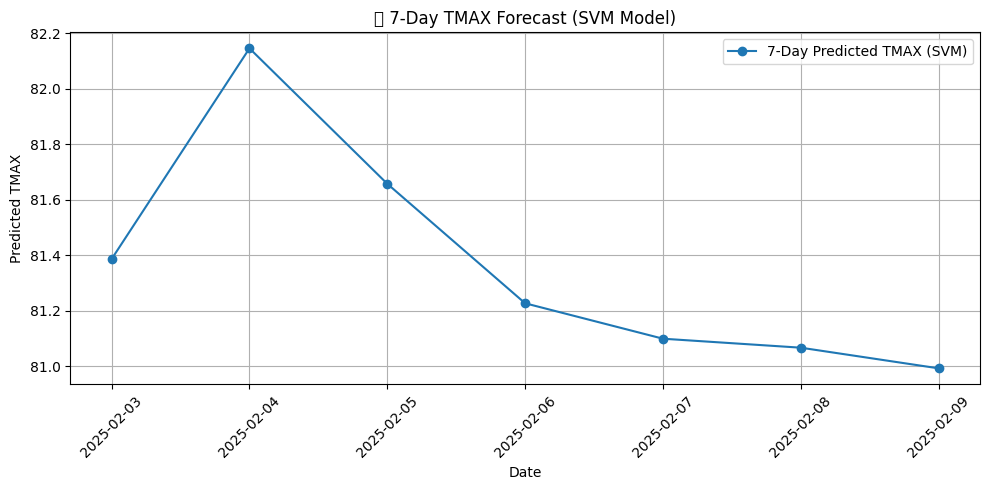

In [ ]:
# 9. Plot
plt.figure(figsize=(10, 5))
plt.plot(forecast_df['DATE'], forecast_df['Predicted_TMAX'], marker='o', label='7-Day Predicted TMAX (SVM)')
plt.xlabel("Date")
plt.ylabel("Predicted TMAX")
plt.title("📈 7-Day TMAX Forecast (SVM Model)")
plt.grid(True)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()



## **LSTM**

In [ ]:
df3 = pd.read_csv("/content/drive/MyDrive/Gaiadhi/imputed_all_stations_data.csv")

In [ ]:
df3.index = pd.to_datetime(df3['DATE'])

In [ ]:
import tensorflow as tf
import os
import pandas as pd
import numpy as np

In [ ]:
#keeping the rows that contains station USC00411048 "BRENHAM, TX US"
df_1=df3[df3['STATION']== 'USC00411048']

In [ ]:
df_1

In [ ]:
#Dropping all other features and using only past values of the temperature to predict the future
from sklearn.preprocessing import LabelEncoder
df_1= df_1.drop(['NAME', 'COUNTY','PRCP','TMIN', 'SOLAR RADIATION','STATION', 'LATITUDE', 'LONGITUDE', 'ELEVATION'], axis=1)

In [ ]:
df_1

In [ ]:
temp = df_1['TMAX']
temp = temp.dropna()
temp.plot()

In [ ]:
def df_to_X_y(df, window_size=5):
  df_as_np = df.to_numpy()
  X = []
  y = []
  for i in range(len(df_as_np)-window_size):
    row = [[a] for a in df_as_np[i:i+window_size]]
    X.append(row)
    label = df_as_np[i+window_size]
    y.append(label)
  return np.array(X), np.array(y)

In [ ]:
WINDOW_SIZE = 5
X1, y1 = df_to_X_y(temp, WINDOW_SIZE)
X1.shape, y1.shape

In [ ]:
## Initial Train-Validation-Test Split
train_size = int(len(X1) * 0.8)  # 80% for training
val_size = int(len(X1) * 0.1)    # 10% for validation

X_train1, X_val1, X_test1 = X1[:train_size], X1[train_size:train_size + val_size], X1[train_size + val_size:]
y_train1, y_val1, y_test1 = y1[:train_size], y1[train_size:train_size + val_size], y1[train_size + val_size:]
X_train1.shape, y_train1.shape, X_val1.shape, y_val1.shape, X_test1.shape, y_test1.shape

In [ ]:
X_train1

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.metrics import RootMeanSquaredError, MeanAbsoluteError
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model

model1 = Sequential()
model1.add(InputLayer((5, 1)))
model1.add(LSTM(64))
model1.add(Dense(8, activation ='relu', kernel_initializer= "he_normal"))
model1.add(Dense(4, activation ='relu', kernel_initializer= "he_normal"))
model1.add(Dense(2, activation ='relu', kernel_initializer= "he_normal"))
model1.add(Dense(1, activation ='linear'))

model1.summary()

In [ ]:
cp1 = ModelCheckpoint('model1.keras', save_best_only=True)
model1.compile(loss=MeanSquaredError(), optimizer=Adam(learning_rate=0.001), metrics=[RootMeanSquaredError(name="rmse"), MeanAbsoluteError(name="mae")])

In [ ]:
model1.fit(X_train1, y_train1, validation_data=(X_val1, y_val1), epochs=1000, callbacks=[cp1])

In [ ]:
# Load the best saved model
model1 = load_model('model1.keras')

# Evaluate on validation set (or test set if preferred)
metrics = model1.evaluate(X_val1, y_val1, verbose=0)

# Extract metrics
loss, rmse, mae = metrics  # Order matches metrics defined in compile()

# Print neatly
print("Best Model Metrics (Validation Set):")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

In [ ]:
from tensorflow.keras.models import load_model
model1 = load_model('model1.keras')

In [ ]:
train_predictions = model1.predict(X_train1).flatten()
train_results = pd.DataFrame(data={'Train Predictions':train_predictions, 'Actuals':y_train1})
train_results

In [ ]:
import matplotlib.pyplot as plt
plt.plot(train_results['Train Predictions'][:50])
plt.plot(train_results['Actuals'][:50])

In [ ]:
val_predictions = model1.predict(X_val1).flatten()
val_results = pd.DataFrame(data={'Val Predictions':val_predictions, 'Actuals':y_val1})
val_results

In [ ]:
plt.plot(val_results['Val Predictions'][:100])
plt.plot(val_results['Actuals'][:100])

In [ ]:
test_predictions = model1.predict(X_test1).flatten()
test_results = pd.DataFrame(data={'Test Predictions':test_predictions, 'Actuals':y_test1})
test_results

In [ ]:
plt.plot(test_results['Test Predictions'][:50])
plt.plot(test_results['Actuals'][:50])

In [ ]:
test_predictions = model1.predict(X_test1).flatten()
test_results = pd.DataFrame(data={'Test Predictions':test_predictions, 'Actuals':y_test1})
test_results

In [ ]:

from datetime import timedelta
# Get the last 5 days of data for prediction
last_5_days = np.array(temp[-5:])
last_5_days = last_5_days.reshape(1,5,1)

# Initialize an empty list to store predictions
future_predictions = []

# Predict the next 14 days
for i in range(14):
    next_day_prediction = model1.predict(last_5_days)[0,0]
    future_predictions.append(next_day_prediction)
    # Update the input sequence for the next prediction
    last_5_days = np.roll(last_5_days, -1)
    last_5_days[0, -1, 0] = next_day_prediction

# Print or use the future_predictions list
print(future_predictions)

# Get the last date in the original time series
last_date = df_1.index[-1]
# Create a date range for the next 14 days
future_dates = [last_date + timedelta(days=i+1) for i in range(14)]

# Create a DataFrame with predicted values and dates
future_df = pd.DataFrame({'Predicted_TMAX': future_predictions}, index=future_dates)

# Concatenate the original 'temp' series with the predicted values
extended_temp = pd.concat([temp, future_df['Predicted_TMAX']])

# Plot the extended data
plt.figure(figsize=(10, 6))
plt.plot(extended_temp.index, extended_temp.values, label='TMAX')
plt.plot(future_df.index, future_df['Predicted_TMAX'], label='14-day Forecast', color='red')
plt.xlabel('Date')
plt.ylabel('TMAX')
plt.title('TMAX Predictions for the next 14 Days')
plt.legend()
plt.show()


In [ ]:
future_df